In [3]:
import sys
import torch

print(sys.executable)
print(torch.__version__)
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("Running on CPU (CUDA GPU unavailable)")

F:\homeworks\data analysis\final\.venv\Scripts\python.exe
2.11.0+cu128
True
NVIDIA GeForce RTX 5060 Laptop GPU


In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
import re
from tqdm import tqdm

PROJECT_DIR = Path.cwd().resolve().parent

CAPTIONS_PATH = PROJECT_DIR / "dataset" / "captions.txt"
IMAGES_DIR = PROJECT_DIR / "dataset" / "Images"

OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
MODELS_DIR = OUTPUT_DIR / "models"

for p in [FIGURES_DIR, TABLES_DIR, MODELS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Captions path:", CAPTIONS_PATH)
print("Captions exists:", CAPTIONS_PATH.exists())
print("Images directory:", IMAGES_DIR)
print("Images directory exists:", IMAGES_DIR.exists())

Project directory: F:\homeworks\data analysis\Flickr8k-Multimodal-NLP
Captions path: F:\homeworks\data analysis\Flickr8k-Multimodal-NLP\dataset\captions.txt
Captions exists: True
Images directory: F:\homeworks\data analysis\Flickr8k-Multimodal-NLP\dataset\Images
Images directory exists: True


In [5]:
captions_df = pd.read_csv(CAPTIONS_PATH)

captions_df.columns = [c.strip().lower() for c in captions_df.columns]

print("Dataset shape:", captions_df.shape)
print("Columns:", captions_df.columns.tolist())

display(captions_df.head(10))

Dataset shape: (40455, 2)
Columns: ['image', 'caption']


,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...
5,1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting
6,1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with...
7,1001773457_577c3a7d70.jpg,A black dog and a white dog with brown spots a...
8,1001773457_577c3a7d70.jpg,Two dogs of different breeds looking at each o...
9,1001773457_577c3a7d70.jpg,Two dogs on pavement moving toward each other .


In [6]:
required_columns = {"image", "caption"}

if not required_columns.issubset(set(captions_df.columns)):
    raise ValueError(f"Required columns are missing. Found columns: {captions_df.columns.tolist()}")

print("Captions file loaded successfully.")
print("Number of rows:", len(captions_df))
print("Number of unique images:", captions_df["image"].nunique())
print("Number of missing captions:", captions_df["caption"].isna().sum())
print("Number of missing image names:", captions_df["image"].isna().sum())

Captions file loaded successfully.
Number of rows: 40455
Number of unique images: 8091
Number of missing captions: 0
Number of missing image names: 0


In [7]:
num_caption_rows = len(captions_df)
num_unique_images = captions_df["image"].nunique()
captions_per_image = captions_df.groupby("image")["caption"].count()

summary_df = pd.DataFrame({
    "Metric": [
        "Total caption rows",
        "Unique images",
        "Minimum captions per image",
        "Maximum captions per image",
        "Mean captions per image"
    ],
    "Value": [
        num_caption_rows,
        num_unique_images,
        captions_per_image.min(),
        captions_per_image.max(),
        captions_per_image.mean()
    ]
})

display(summary_df)

summary_df.to_csv(TABLES_DIR / "01_dataset_basic_summary.csv", index=False)

,Metric,Value
0,Total caption rows,40455.0
1,Unique images,8091.0
2,Minimum captions per image,5.0
3,Maximum captions per image,5.0
4,Mean captions per image,5.0


In [8]:
caption_images = set(captions_df["image"].unique())
folder_images = set([p.name for p in IMAGES_DIR.glob("*") if p.is_file()])

missing_images = sorted(list(caption_images - folder_images))
extra_images = sorted(list(folder_images - caption_images))

print("Images mentioned in captions:", len(caption_images))
print("Images found in Images folder:", len(folder_images))
print("Missing images:", len(missing_images))
print("Extra images:", len(extra_images))

missing_df = pd.DataFrame({"missing_image": missing_images})
extra_df = pd.DataFrame({"extra_image": extra_images})

display(missing_df.head())
display(extra_df.head())

missing_df.to_csv(TABLES_DIR / "02_missing_images.csv", index=False)
extra_df.to_csv(TABLES_DIR / "03_extra_images.csv", index=False)

Images mentioned in captions: 8091
Images found in Images folder: 8091
Missing images: 0
Extra images: 0


,missing_image


,extra_image


In [9]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def clean_caption_for_eda(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

captions_df["clean_caption"] = captions_df["caption"].apply(clean_caption_for_eda)
captions_df["caption_length"] = captions_df["clean_caption"].apply(lambda x: len(x.split()))

caption_length_summary = captions_df["caption_length"].describe()

display(captions_df.head(10))
display(caption_length_summary)

caption_length_summary.to_csv(TABLES_DIR / "04_caption_length_summary.csv")

,image,caption,clean_caption,caption_length
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...,a child in a pink dress is climbing up a set o...,17
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .,a girl going into a wooden building,7
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .,a little girl climbing into a wooden playhouse,8
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...,a little girl climbing the stairs to her playh...,9
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...,a little girl in a pink dress going into a woo...,12
5,1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting,a black dog and a spotted dog are fighting,9
6,1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with...,a black dog and a tri colored dog playing with...,15
7,1001773457_577c3a7d70.jpg,A black dog and a white dog with brown spots a...,a black dog and a white dog with brown spots a...,18
8,1001773457_577c3a7d70.jpg,Two dogs of different breeds looking at each o...,two dogs of different breeds looking at each o...,12
9,1001773457_577c3a7d70.jpg,Two dogs on pavement moving toward each other .,two dogs on pavement moving toward each other,8


count    40455.000000
mean        10.812730
std          3.767733
min          1.000000
25%          8.000000
50%         10.000000
75%         13.000000
max         36.000000
Name: caption_length, dtype: float64

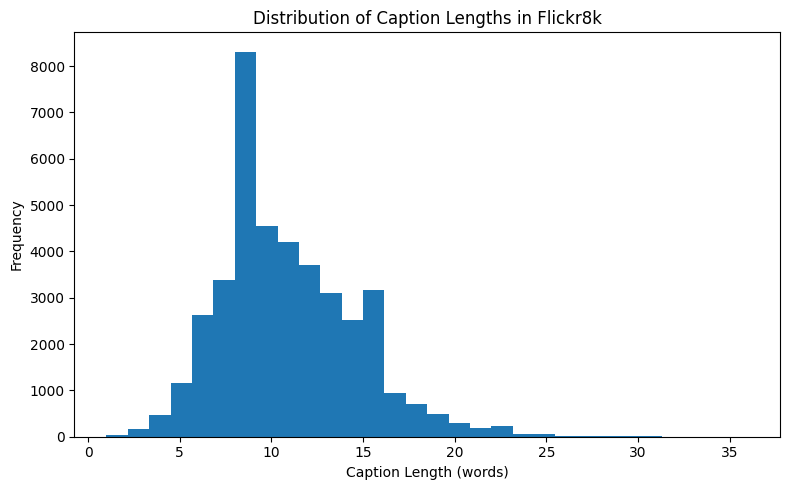

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(captions_df["caption_length"], bins=30)
plt.xlabel("Caption Length (words)")
plt.ylabel("Frequency")
plt.title("Distribution of Caption Lengths in Flickr8k")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_caption_length_distribution.png", dpi=300)
plt.show()

Total words: 437429
Vocabulary size: 8441


,word,frequency
0,a,62992
1,in,18986
2,the,18419
3,on,10745
4,is,9345
5,and,8862
6,dog,8138
7,with,7765
8,man,7274
9,of,6723


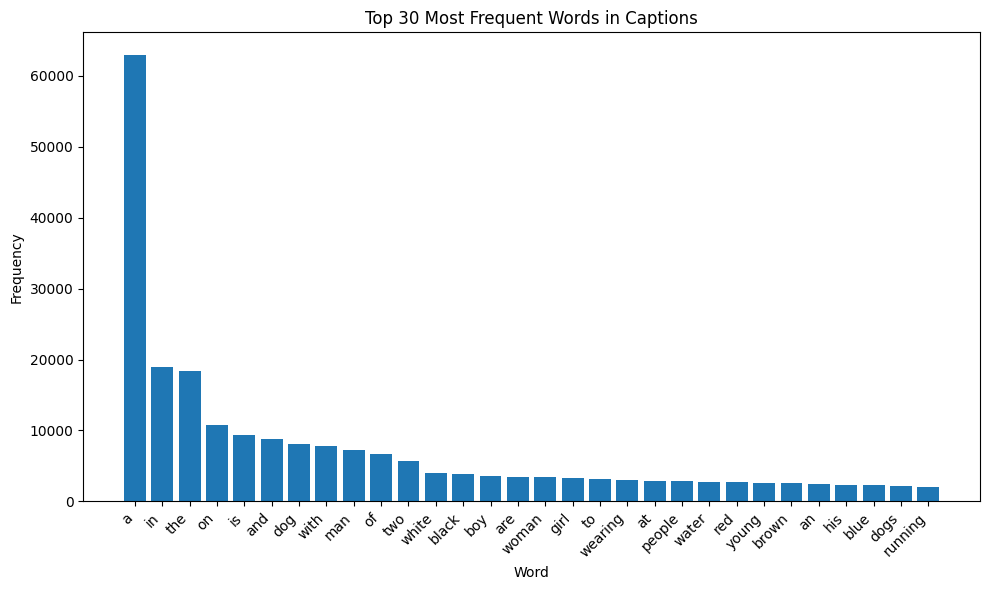

In [11]:
all_words = []

for cap in captions_df["clean_caption"]:
    all_words.extend(cap.split())

word_counts = Counter(all_words)

vocab_size = len(word_counts)
total_words = len(all_words)

print("Total words:", total_words)
print("Vocabulary size:", vocab_size)

top_words_df = pd.DataFrame(word_counts.most_common(30), columns=["word", "frequency"])
display(top_words_df)

top_words_df.to_csv(TABLES_DIR / "05_top_30_words.csv", index=False)

plt.figure(figsize=(10, 6))
plt.bar(top_words_df["word"], top_words_df["frequency"])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.title("Top 30 Most Frequent Words in Captions")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_top_30_words.png", dpi=300)
plt.show()

In [12]:
# #AFTER removing stopword
# custom_stopwords = {
#     "a", "an", "the",
#     "is", "are", "was", "were", "be", "been", "being", "am",
#     "in", "on", "at", "by", "for", "from", "to", "of", "with", "without",
#     "and", "or", "but",
#     "as", "than", "then",
#     "this", "that", "these", "those",
#     "it", "its",
#     "he", "she", "they", "them", "his", "her", "their",
#     "there", "here",
#     "into", "onto", "over", "under", "through", "across", "between",
#     "up", "down", "out", "off",
#     "while", "during",
#     "near", "next", "front", "behind",
#     "each", "other",
#     "some", "many", "several",
#     "one", "two", "three",
#     "very"
# }

# all_words_no_stop = [
#     word for word in all_words
#     if word not in custom_stopwords and len(word) > 1
# ]

# word_counts_no_stop = Counter(all_words_no_stop)

# semantic_total_words = len(all_words_no_stop)
# semantic_vocab_size = len(word_counts_no_stop)

# print("Total words after stopword removal:", semantic_total_words)
# print("Vocabulary size after stopword removal:", semantic_vocab_size)

# top_words_no_stop_df = pd.DataFrame(
#     word_counts_no_stop.most_common(30),
#     columns=["word", "frequency"]
# )

# display(top_words_no_stop_df)

# top_words_no_stop_df.to_csv(
#     TABLES_DIR / "06_top_30_semantic_words_without_stopwords.csv",
#     index=False
# )

# plt.figure(figsize=(10, 6))
# plt.bar(top_words_no_stop_df["word"], top_words_no_stop_df["frequency"])
# plt.xticks(rotation=45, ha="right")
# plt.xlabel("Word")
# plt.ylabel("Frequency")
# plt.title("Top 30 Semantic Words After Stopword Removal")
# plt.tight_layout()
# plt.savefig(FIGURES_DIR / "03_top_30_semantic_words_without_stopwords.png", dpi=300)
# plt.show()

In [13]:
# #comparing with and without stopword

# vocabulary_comparison_df = pd.DataFrame({
#     "Metric": [
#         "Total words before stopword removal",
#         "Vocabulary size before stopword removal",
#         "Total words after stopword removal",
#         "Vocabulary size after stopword removal"
#     ],
#     "Value": [
#         total_words,
#         vocab_size,
#         semantic_total_words,
#         semantic_vocab_size
#     ]
# })

# display(vocabulary_comparison_df)

# vocabulary_comparison_df.to_csv(
#     TABLES_DIR / "07_vocabulary_raw_vs_semantic_summary.csv",
#     index=False
# )

Total words after stopword removal v2: 250557
Vocabulary size after stopword removal v2: 8360


,word,frequency
0,dog,8138
1,man,7274
2,two,5642
3,white,3959
4,black,3848
5,boy,3581
6,woman,3402
7,girl,3328
8,wearing,3062
9,people,2883


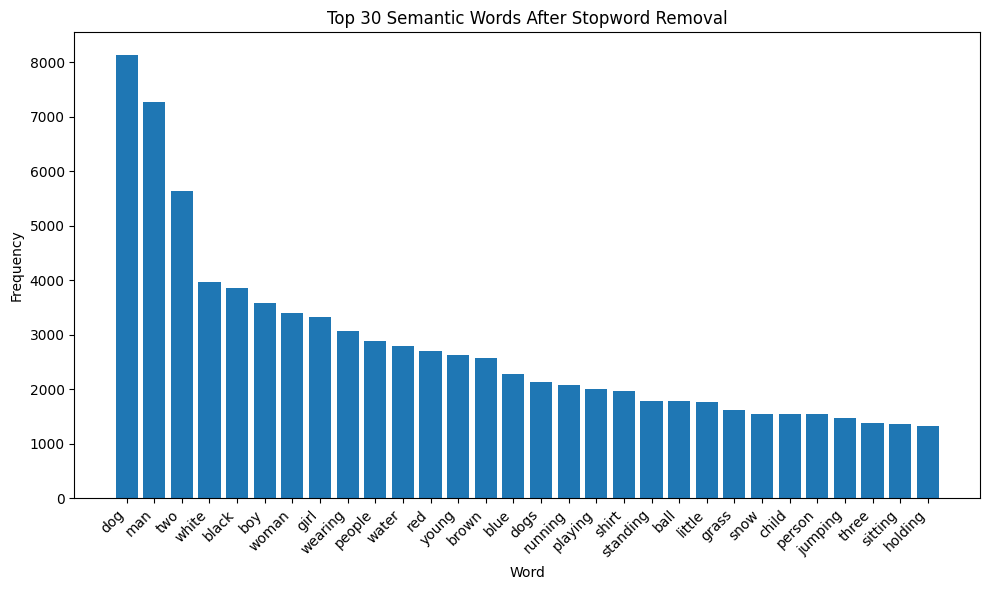

In [14]:
# after removing stopwords
# updated:keeping one, two, three

custom_stopwords_v2 = {
    "a", "an", "the",
    "is", "are", "was", "were", "be", "been", "being", "am",
    "in", "on", "at", "by", "for", "from", "to", "of", "with", "without",
    "and", "or", "but",
    "as", "than", "then",
    "this", "that", "these", "those",
    "it", "its",
    "he", "she", "they", "them", "his", "her", "their",
    "there", "here",
    "into", "onto", "over", "under", "through", "across", "between",
    "up", "down", "out", "off",
    "while", "during",
    "near", "next", "front", "behind",
    "each", "other",
    "some", "many", "several",
    "very"
}

all_words_no_stop_v2 = [
    word for word in all_words
    if word not in custom_stopwords_v2 and len(word) > 1
]

word_counts_no_stop_v2 = Counter(all_words_no_stop_v2)

semantic_total_words_v2 = len(all_words_no_stop_v2)
semantic_vocab_size_v2 = len(word_counts_no_stop_v2)

print("Total words after stopword removal v2:", semantic_total_words_v2)
print("Vocabulary size after stopword removal v2:", semantic_vocab_size_v2)

top_words_no_stop_v2_df = pd.DataFrame(
    word_counts_no_stop_v2.most_common(30),
    columns=["word", "frequency"]
)

display(top_words_no_stop_v2_df)

top_words_no_stop_v2_df.to_csv(
    TABLES_DIR / "06_top_30_semantic_words_without_stopwords_v2.csv",
    index=False
)

plt.figure(figsize=(10, 6))
plt.bar(top_words_no_stop_v2_df["word"], top_words_no_stop_v2_df["frequency"])
plt.xticks(rotation=45, ha="right")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.title("Top 30 Semantic Words After Stopword Removal")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_top_30_semantic_words_without_stopwords_v2.png", dpi=300)
plt.show()

In [15]:
#rare words

freq_values = np.array(list(word_counts.values()))

rare_summary = pd.DataFrame({
    "Condition": ["freq = 1", "freq <= 2", "freq <= 3", "freq <= 5", "freq <= 10"],
    "Number of words": [
        np.sum(freq_values == 1),
        np.sum(freq_values <= 2),
        np.sum(freq_values <= 3),
        np.sum(freq_values <= 5),
        np.sum(freq_values <= 10)
    ]
})

rare_summary["Percent of vocabulary"] = rare_summary["Number of words"] / vocab_size * 100

display(rare_summary)

rare_summary.to_csv(TABLES_DIR / "07_rare_words_summary.csv", index=False)

,Condition,Number of words,Percent of vocabulary
0,freq = 1,3310,39.213363
1,freq <= 2,4375,51.830352
2,freq <= 3,5032,59.613790
3,freq <= 5,5797,68.676697
4,freq <= 10,6591,78.083166


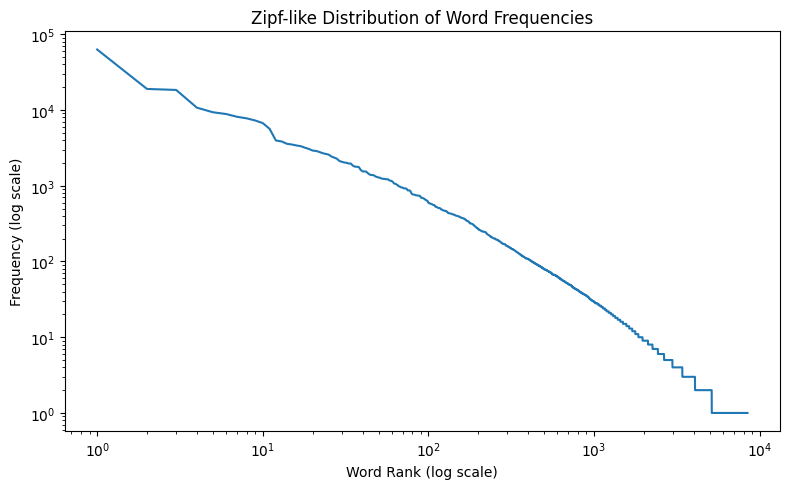

In [16]:

sorted_freqs = np.array(sorted(word_counts.values(), reverse=True))
ranks = np.arange(1, len(sorted_freqs) + 1)

plt.figure(figsize=(8, 5))
plt.loglog(ranks, sorted_freqs)
plt.xlabel("Word Rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.title("Zipf-like Distribution of Word Frequencies")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_zipf_word_frequency.png", dpi=300)
plt.show()

In [17]:
#choosing min_freq

coverage_rows = []

thresholds = [1, 2, 3, 5, 10]

for min_freq in thresholds:
    kept_words = {word for word, freq in word_counts.items() if freq >= min_freq}
    
    kept_vocab_size = len(kept_words)
    removed_vocab_size = vocab_size - kept_vocab_size
    
    kept_token_count = sum(freq for word, freq in word_counts.items() if word in kept_words)
    removed_token_count = total_words - kept_token_count
    
    token_coverage = kept_token_count / total_words * 100
    removed_vocab_percent = removed_vocab_size / vocab_size * 100
    
    coverage_rows.append({
        "min_freq": min_freq,
        "kept_vocab_size": kept_vocab_size,
        "removed_vocab_size": removed_vocab_size,
        "removed_vocab_percent": removed_vocab_percent,
        "kept_token_count": kept_token_count,
        "removed_token_count": removed_token_count,
        "token_coverage_percent": token_coverage
    })

vocab_coverage_df = pd.DataFrame(coverage_rows)

display(vocab_coverage_df)

vocab_coverage_df.to_csv(
    TABLES_DIR / "08_vocabulary_coverage_by_min_freq.csv",
    index=False
)

,min_freq,kept_vocab_size,removed_vocab_size,removed_vocab_percent,kept_token_count,removed_token_count,token_coverage_percent
0,1,8441,0,0.000000,437429,0,100.000000
1,2,5131,3310,39.213363,434119,3310,99.243306
2,3,4066,4375,51.830352,431989,5440,98.756370
3,5,2971,5470,64.802748,428266,9163,97.905260
4,10,1961,6480,76.768155,421621,15808,96.386156


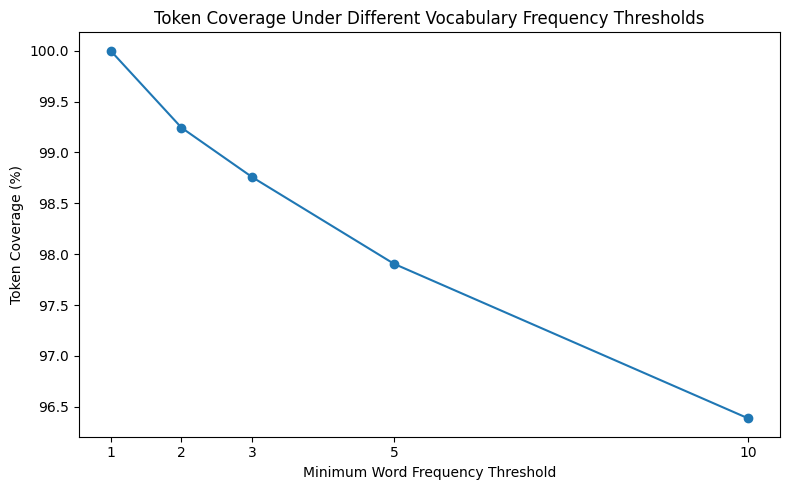

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(vocab_coverage_df["min_freq"], vocab_coverage_df["token_coverage_percent"], marker="o")
plt.xlabel("Minimum Word Frequency Threshold")
plt.ylabel("Token Coverage (%)")
plt.title("Token Coverage Under Different Vocabulary Frequency Thresholds")
plt.xticks(vocab_coverage_df["min_freq"])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_token_coverage_by_min_freq.png", dpi=300)
plt.show()

In [19]:
#checking images

from PIL import Image
from tqdm import tqdm

image_info = []
corrupted_images = []

unique_images = captions_df["image"].unique()

for img_name in tqdm(unique_images, desc="Reading image sizes"):
    img_path = IMAGES_DIR / img_name
    
    try:
        with Image.open(img_path) as img:
            width, height = img.size
            image_info.append({
                "image": img_name,
                "width": width,
                "height": height,
                "aspect_ratio": width / height
            })
    except Exception as e:
        corrupted_images.append({
            "image": img_name,
            "error": str(e)
        })

image_info_df = pd.DataFrame(image_info)
corrupted_images_df = pd.DataFrame(corrupted_images)

print("Valid images:", len(image_info_df))
print("Corrupted images:", len(corrupted_images_df))

display(image_info_df.describe())
display(corrupted_images_df.head())

image_info_df.to_csv(TABLES_DIR / "09_image_size_info.csv", index=False)
corrupted_images_df.to_csv(TABLES_DIR / "10_corrupted_images.csv", index=False)

Reading image sizes: 100%|██████████████████████████████████████████████████| 8091/8091 [00:31<00:00, 259.26it/s]

Valid images: 8091
Corrupted images: 0


,width,height,aspect_ratio
count,8091.000000,8091.000000,8091.000000
mean,457.872204,397.251885,1.219682
std,68.659411,75.670168,0.361616
min,164.000000,127.000000,0.328000
25%,400.000000,333.000000,0.800000
50%,500.000000,375.000000,1.333333
75%,500.000000,500.000000,1.501502
max,500.000000,500.000000,3.937008


""


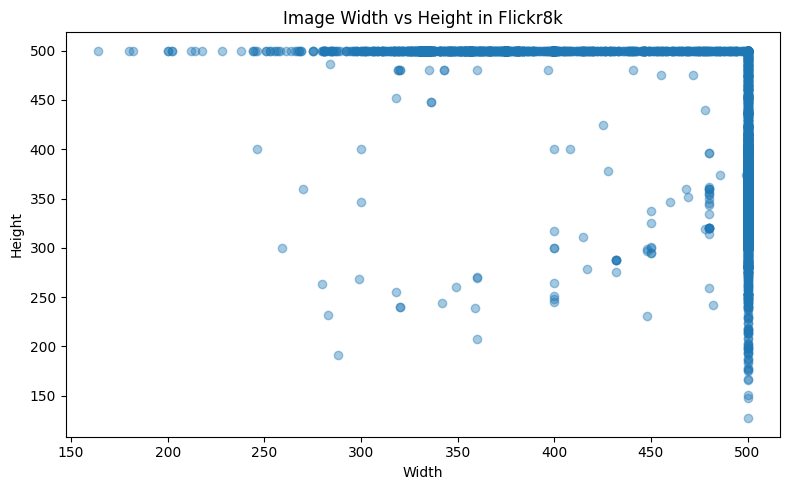

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(image_info_df["width"], image_info_df["height"], alpha=0.4)
plt.xlabel("Width")
plt.ylabel("Height")
plt.title("Image Width vs Height in Flickr8k")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_image_width_height_scatter.png", dpi=300)
plt.show()

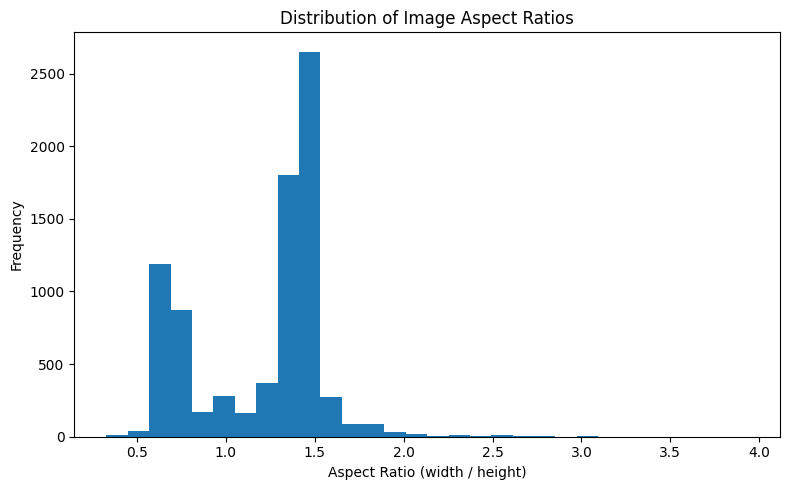

In [21]:
plt.figure(figsize=(8, 5))
plt.hist(image_info_df["aspect_ratio"], bins=30)
plt.xlabel("Aspect Ratio (width / height)")
plt.ylabel("Frequency")
plt.title("Distribution of Image Aspect Ratios")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_image_aspect_ratio_distribution.png", dpi=300)
plt.show()

In [22]:

# decision for preprocessing

preprocessing_decisions_df = pd.DataFrame({
    "Component": [
        "Captions file integrity",
        "Image file integrity",
        "Text lowercasing",
        "Punctuation removal for EDA",
        "Stopword removal",
        "Rare word handling for caption model",
        "Selected min_freq",
        "Image resizing",
        "Image encoder"
    ],
    "Decision": [
        "All caption rows were successfully loaded.",
        "All 8091 images were valid and readable; no corrupted image was detected.",
        "Captions are converted to lowercase for consistent text processing.",
        "Non-alphabetic characters are removed only for EDA and vocabulary analysis.",
        "Stopwords are removed only for semantic word-frequency analysis, not for caption generation.",
        "Rare words are replaced with <unk> in the caption-generation vocabulary.",
        "min_freq = 5",
        "All images are resized to 224 × 224 before CNN-based feature extraction.",
        "A pretrained ResNet50 encoder is used for visual feature extraction."
    ],
    "Justification": [
        "The captions file contains 40455 rows and 8091 unique images with exactly five captions per image.",
        "Missing images = 0 and corrupted images = 0, so no image removal is required.",
        "Lowercasing reduces duplicate word forms such as Dog and dog.",
        "This simplifies statistical analysis of caption length and word frequencies.",
        "Stopwords dominate raw frequency counts but carry limited semantic information for content analysis.",
        "A large portion of the vocabulary is rare, which can increase overfitting in sequence generation.",
        "This threshold keeps 97.90% of all text tokens while reducing the vocabulary to 2971 words.",
        "CNN encoders require fixed-size image tensors.",
        "Using a pretrained encoder reduces computational cost and overfitting risk on Flickr8k."
    ]
})

display(preprocessing_decisions_df)

preprocessing_decisions_df.to_csv(
    TABLES_DIR / "11_preprocessing_decisions.csv",
    index=False
)

,Component,Decision,Justification
0,Captions file integrity,All caption rows were successfully loaded.,The captions file contains 40455 rows and 8091...
1,Image file integrity,All 8091 images were valid and readable; no co...,"Missing images = 0 and corrupted images = 0, s..."
2,Text lowercasing,Captions are converted to lowercase for consis...,Lowercasing reduces duplicate word forms such ...
3,Punctuation removal for EDA,Non-alphabetic characters are removed only for...,This simplifies statistical analysis of captio...
4,Stopword removal,Stopwords are removed only for semantic word-f...,Stopwords dominate raw frequency counts but ca...
5,Rare word handling for caption model,Rare words are replaced with <unk> in the capt...,"A large portion of the vocabulary is rare, whi..."
6,Selected min_freq,min_freq = 5,This threshold keeps 97.90% of all text tokens...
7,Image resizing,All images are resized to 224 × 224 before CNN...,CNN encoders require fixed-size image tensors.
8,Image encoder,A pretrained ResNet50 encoder is used for visu...,Using a pretrained encoder reduces computation...


In [23]:
# train/validation/test based on images

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

all_unique_images = np.array(sorted(captions_df["image"].unique()))

train_images, temp_images = train_test_split(
    all_unique_images,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

val_images, test_images = train_test_split(
    temp_images,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)

train_df = captions_df[captions_df["image"].isin(train_images)].reset_index(drop=True)
val_df = captions_df[captions_df["image"].isin(val_images)].reset_index(drop=True)
test_df = captions_df[captions_df["image"].isin(test_images)].reset_index(drop=True)

split_summary_df = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Unique images": [
        train_df["image"].nunique(),
        val_df["image"].nunique(),
        test_df["image"].nunique()
    ],
    "Caption rows": [
        len(train_df),
        len(val_df),
        len(test_df)
    ]
})

display(split_summary_df)

split_summary_df.to_csv(TABLES_DIR / "12_data_split_summary.csv", index=False)

train_df.to_csv(TABLES_DIR / "train_captions.csv", index=False)
val_df.to_csv(TABLES_DIR / "val_captions.csv", index=False)
test_df.to_csv(TABLES_DIR / "test_captions.csv", index=False)

,Split,Unique images,Caption rows
0,Train,5663,28315
1,Validation,1214,6070
2,Test,1214,6070


In [24]:
#checking

train_set = set(train_df["image"].unique())
val_set = set(val_df["image"].unique())
test_set = set(test_df["image"].unique())

overlap_train_val = train_set.intersection(val_set)
overlap_train_test = train_set.intersection(test_set)
overlap_val_test = val_set.intersection(test_set)

print("Train-Val overlap:", len(overlap_train_val))
print("Train-Test overlap:", len(overlap_train_test))
print("Val-Test overlap:", len(overlap_val_test))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [25]:
# make text(join captions) for each image

caption_by_image_df = (
    captions_df
    .groupby("image")["clean_caption"]
    .apply(lambda caps: " ".join(caps))
    .reset_index()
)

caption_by_image_df = caption_by_image_df.sort_values("image").reset_index(drop=True)

image_names = caption_by_image_df["image"].tolist()
image_texts = caption_by_image_df["clean_caption"].tolist()

print("Number of image-level text documents:", len(image_texts))
display(caption_by_image_df.head())

Number of image-level text documents: 8091


,image,clean_caption
0,1000268201_693b08cb0e.jpg,a child in a pink dress is climbing up a set o...
1,1001773457_577c3a7d70.jpg,a black dog and a spotted dog are fighting a b...
2,1002674143_1b742ab4b8.jpg,a little girl covered in paint sits in front o...
3,1003163366_44323f5815.jpg,a man lays on a bench while his dog sits by hi...
4,1007129816_e794419615.jpg,a man in an orange hat starring at something a...


In [26]:

custom_stopwords_v2 = {
    "a", "an", "the",
    "is", "are", "was", "were", "be", "been", "being", "am",
    "in", "on", "at", "by", "for", "from", "to", "of", "with", "without",
    "and", "or", "but",
    "as", "than", "then",
    "this", "that", "these", "those",
    "it", "its",
    "he", "she", "they", "them", "his", "her", "their",
    "there", "here",
    "into", "onto", "over", "under", "through", "across", "between",
    "up", "down", "out", "off",
    "while", "during",
    "near", "next", "front", "behind",
    "each", "other",
    "some", "many", "several",
    "very"
}

tfidf_stopwords = sorted(list(custom_stopwords_v2))

print("Number of custom TF-IDF stopwords:", len(tfidf_stopwords))
print(tfidf_stopwords[:20])

Number of custom TF-IDF stopwords: 65
['a', 'across', 'am', 'an', 'and', 'are', 'as', 'at', 'be', 'been', 'behind', 'being', 'between', 'but', 'by', 'down', 'during', 'each', 'for', 'from']


In [27]:
#choose best ngram,min_df

from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

tfidf_experiment_no_cap_rows = []

ngram_options = [(1, 1), (1, 2), (1, 3)]
min_df_options = [1, 2, 5]

for ngram in ngram_options:
    for min_df_value in min_df_options:
        vectorizer_temp = TfidfVectorizer(
            stop_words=tfidf_stopwords,
            max_features=None,
            ngram_range=ngram,
            min_df=min_df_value
        )
        
        X_temp = vectorizer_temp.fit_transform(image_texts)
        
        tfidf_experiment_no_cap_rows.append({
            "ngram_range": str(ngram),
            "min_df": min_df_value,
            "tfidf_shape_without_cap": str(X_temp.shape),
            "number_of_features_without_cap": X_temp.shape[1],
            "matrix_density_percent": (X_temp.nnz / (X_temp.shape[0] * X_temp.shape[1])) * 100
        })

tfidf_sensitivity_no_cap_df = pd.DataFrame(tfidf_experiment_no_cap_rows)

display(tfidf_sensitivity_no_cap_df)

tfidf_sensitivity_no_cap_df.to_csv(
    TABLES_DIR / "20_tfidf_sensitivity_without_max_features.csv",
    index=False
)

,ngram_range,min_df,tfidf_shape_without_cap,number_of_features_without_cap,matrix_density_percent
0,"(1, 1)",1,"(8091, 8360)",8360,0.225420
1,"(1, 1)",2,"(8091, 4734)",4734,0.388614
2,"(1, 1)",5,"(8091, 2578)",2578,0.686139
3,"(1, 2)",1,"(8091, 101896)",101896,0.044129
4,"(1, 2)",2,"(8091, 28433)",28433,0.126211
5,"(1, 2)",5,"(8091, 9124)",9124,0.327500
6,"(1, 3)",1,"(8091, 283044)",283044,0.025710
7,"(1, 3)",2,"(8091, 45854)",45854,0.094769
8,"(1, 3)",5,"(8091, 11651)",11651,0.283727


In [28]:
#ngram_range=(1, 2)
#min_df=2
#max_features=5000

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
import joblib
import numpy as np

CACHE_DIR = PROJECT_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

tfidf_vectorizer = TfidfVectorizer(
    stop_words=tfidf_stopwords,
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = tfidf_vectorizer.fit_transform(image_texts)

svd_text = TruncatedSVD(n_components=256, random_state=42)
X_text_svd = svd_text.fit_transform(X_tfidf)
X_text_svd = normalize(X_text_svd)

explained_variance = svd_text.explained_variance_ratio_.sum()

print("TF-IDF shape:", X_tfidf.shape)
print("Text embedding shape after SVD:", X_text_svd.shape)
print("Explained variance by 256 SVD components:", explained_variance)

np.save(CACHE_DIR / "text_embeddings_tfidf_svd.npy", X_text_svd)
joblib.dump(tfidf_vectorizer, CACHE_DIR / "tfidf_vectorizer.joblib")
joblib.dump(svd_text, CACHE_DIR / "svd_text_model.joblib")

TF-IDF shape: (8091, 5000)
Text embedding shape after SVD: (8091, 256)
Explained variance by 256 SVD components: 0.48765554161199437


['F:\\homeworks\\data analysis\\Flickr8k-Multimodal-NLP\\cache\\svd_text_model.joblib']

In [29]:
# Check selected TF-IDF features

tfidf_features = tfidf_vectorizer.get_feature_names_out()

print("Number of TF-IDF features:", len(tfidf_features))

important_terms = [
    "dog", "man", "two", "three",
    "white dog", "playing ball", "red shirt", "young boy"
]

for term in important_terms:
    print(f"{term}:", term in tfidf_features)

Number of TF-IDF features: 5000
dog: True
man: True
two: True
three: True
white dog: True
playing ball: True
red shirt: True
young boy: True


In [30]:
#save info

text_feature_decision_df = pd.DataFrame({
    "Component": [
        "Text document unit",
        "Vectorization method",
        "Stopword handling",
        "N-gram range",
        "min_df",
        "max_features",
        "Dimensionality reduction",
        "Final text embedding size",
        "Explained variance"
    ],
    "Decision": [
        "The five captions of each image were concatenated into one image-level document.",
        "TF-IDF",
        "Custom English stopwords were removed, while numerical words such as one, two, and three were preserved.",
        "(1, 2)",
        "2",
        "5000",
        "Truncated SVD",
        "256",
        explained_variance
    ],
    "Justification": [
        "The image is the main multimodal unit; therefore, all captions describing the same image were combined.",
        "TF-IDF provides an interpretable sparse representation of caption vocabulary.",
        "Stopwords dominate raw counts but carry limited semantic content; numerical words may describe visible objects.",
        "Unigrams capture objects and actions, while bigrams capture short semantic phrases such as white dog and playing ball.",
        "Terms appearing in only one image-level document were removed to reduce noise.",
        "The feature space was capped to control dimensionality and computational cost.",
        "SVD converts sparse TF-IDF features into compact dense vectors.",
        "A 256-dimensional representation balances compactness and semantic coverage.",
        f"The 256 SVD components explain approximately {explained_variance:.4f} of TF-IDF variance."
    ]
})

display(text_feature_decision_df)

text_feature_decision_df.to_csv(
    TABLES_DIR / "21_final_text_feature_extraction_decisions.csv",
    index=False
)

,Component,Decision,Justification
0,Text document unit,The five captions of each image were concatena...,The image is the main multimodal unit; therefo...
1,Vectorization method,TF-IDF,TF-IDF provides an interpretable sparse repres...
2,Stopword handling,"Custom English stopwords were removed, while n...",Stopwords dominate raw counts but carry limite...
3,N-gram range,"(1, 2)","Unigrams capture objects and actions, while bi..."
4,min_df,2,Terms appearing in only one image-level docume...
5,max_features,5000,The feature space was capped to control dimens...
6,Dimensionality reduction,Truncated SVD,SVD converts sparse TF-IDF features into compa...
7,Final text embedding size,256,A 256-dimensional representation balances comp...
8,Explained variance,0.487656,The 256 SVD components explain approximately 0...


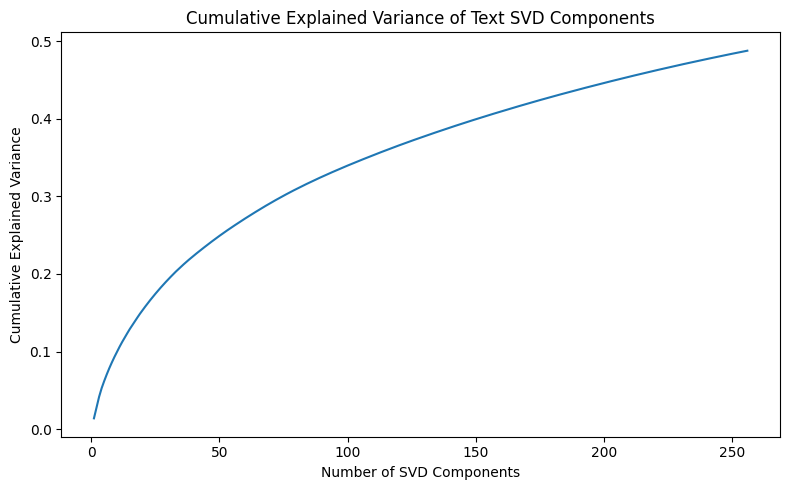

In [31]:
#SVD

cumulative_variance = np.cumsum(svd_text.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.xlabel("Number of SVD Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance of Text SVD Components")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_text_svd_cumulative_explained_variance.png", dpi=300)
plt.show()

In [32]:
# Caption-caption similarity analysis with Nearest Neighbors

from sklearn.neighbors import NearestNeighbors

text_nn = NearestNeighbors(n_neighbors=6, metric="cosine")
text_nn.fit(X_text_svd)

text_distances, text_indices = text_nn.kneighbors(X_text_svd)

print("Text neighbor indices shape:", text_indices.shape)
print("Text neighbor distances shape:", text_distances.shape)

Text neighbor indices shape: (8091, 6)
Text neighbor distances shape: (8091, 6)


In [33]:
# text_neighbors

np.random.seed(42)
sample_indices = np.random.choice(len(image_names), size=5, replace=False)

text_neighbor_rows = []

for idx in sample_indices:
    query_image = image_names[idx]
    neighbor_ids = text_indices[idx][1:]
    neighbor_names = [image_names[j] for j in neighbor_ids]
    neighbor_distances = [text_distances[idx][k] for k in range(1, 6)]
    
    query_caption_sample = captions_df[captions_df["image"] == query_image]["caption"].iloc[0]
    
    text_neighbor_rows.append({
        "query_image": query_image,
        "query_caption_sample": query_caption_sample,
        "nearest_text_neighbors": ", ".join(neighbor_names),
        "cosine_distances": ", ".join([f"{d:.4f}" for d in neighbor_distances])
    })

text_neighbor_df = pd.DataFrame(text_neighbor_rows)

display(text_neighbor_df)

text_neighbor_df.to_csv(
    TABLES_DIR / "22_text_nearest_neighbors_examples.csv",
    index=False
)

,query_image,query_caption_sample,nearest_text_neighbors,cosine_distances
0,3139895886_5a6d495b13.jpg,"A black-and-white dog bounds off the ground , ...","2084103826_ffd76b1e3e.jpg, 2792409624_2731b107...","0.1485, 0.1634, 0.1862, 0.1888, 0.2053"
1,3133825703_359a0c414d.jpg,A child staring at Santa .,"2622517932_57c52c376f.jpg, 1244485675_822e6efe...","0.3933, 0.4039, 0.4140, 0.4528, 0.4863"
2,244910177_7c4ec3f65b.jpg,Three woman walk down a city street and one ha...,"1776981714_5b224d0f7a.jpg, 2695001634_127fe2f0...","0.2027, 0.2417, 0.2596, 0.2627, 0.2639"
3,2127207912_9298824e66.jpg,"The two people are standing on a rock , holdin...","405534993_5158644f98.jpg, 508958120_afe274f726...","0.2483, 0.2890, 0.3002, 0.3295, 0.3463"
4,1810651611_35aae644fb.jpg,A closeup of a little girl on a swing .,"1682079482_9a72fa57fa.jpg, 1561658940_a947f244...","0.1762, 0.1861, 0.2170, 0.2305, 0.2382"


In [34]:
# show text_neighbors
def print_text_neighbors(query_idx, top_k=5):
    query_image = image_names[query_idx]
    query_caps = captions_df[captions_df["image"] == query_image]["caption"].tolist()
    
    print("=" * 100)
    print("QUERY IMAGE:", query_image)
    print("QUERY CAPTIONS:")
    for i, cap in enumerate(query_caps, 1):
        print(f"  {i}. {cap}")
    
    print("\nTEXT NEIGHBORS:")
    for rank in range(1, top_k + 1):
        neighbor_idx = text_indices[query_idx][rank]
        neighbor_image = image_names[neighbor_idx]
        distance = text_distances[query_idx][rank]
        neighbor_caps = captions_df[captions_df["image"] == neighbor_image]["caption"].tolist()
        
        print("-" * 80)
        print(f"Rank {rank} | Image: {neighbor_image} | Cosine distance: {distance:.4f}")
        print("Sample captions:")
        for cap in neighbor_caps[:2]:
            print(f"  - {cap}")

for idx in sample_indices[:3]:
    print_text_neighbors(idx, top_k=5)

QUERY IMAGE: 3139895886_5a6d495b13.jpg
QUERY CAPTIONS:
  1. A black-and-white dog bounds off the ground , all feet in the air , of a yellow field .
  2. A black and white dog is jumping over high yellow grass .
  3. A black and white dog is jumping through a field of brown grass .
  4. a dog runs through the dry grass .
  5. The black and white dog runs through the field .

TEXT NEIGHBORS:
--------------------------------------------------------------------------------
Rank 1 | Image: 2084103826_ffd76b1e3e.jpg | Cosine distance: 0.1485
Sample captions:
  - A black and white dog is jumping in the grass .
  - A black and white dog is running with a muzzle .
--------------------------------------------------------------------------------
Rank 2 | Image: 2792409624_2731b1072c.jpg | Cosine distance: 0.1634
Sample captions:
  - A black and white dog is drooling whilst walking on the grass .
  - A black and white dog is running through grass .
-------------------------------------------------

Text PCA explained variance ratio: [0.0469655  0.02642183]
Total explained variance in 2D: 0.07338733632793193


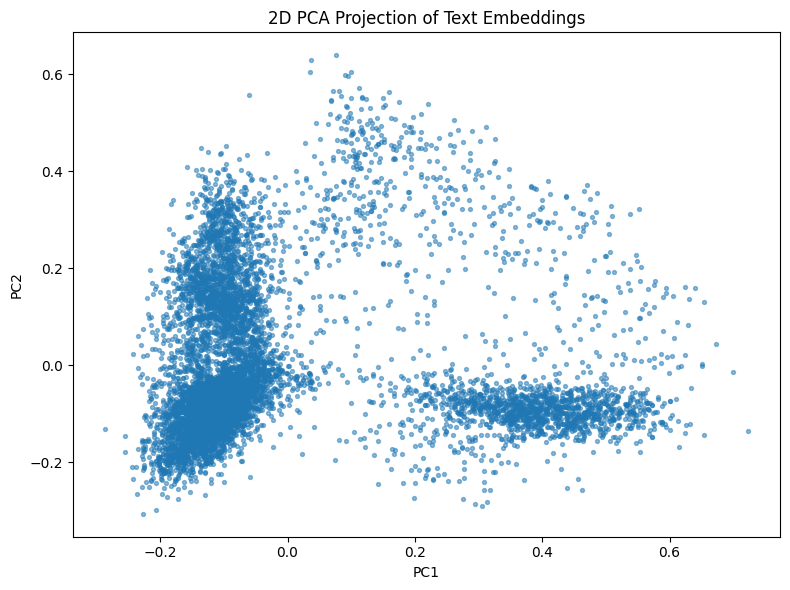

In [35]:
# 2D representation of text embeddings with PCA

from sklearn.decomposition import PCA

pca_text = PCA(n_components=2, random_state=42)
X_text_pca_2d = pca_text.fit_transform(X_text_svd)

print("Text PCA explained variance ratio:", pca_text.explained_variance_ratio_)
print("Total explained variance in 2D:", pca_text.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
plt.scatter(X_text_pca_2d[:, 0], X_text_pca_2d[:, 1], s=8, alpha=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("2D PCA Projection of Text Embeddings")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_text_embedding_pca_2d.png", dpi=300)
plt.show()

In [36]:
# Extract visual features using pretrained ResNet50

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
from tqdm import tqdm
import numpy as np
import pandas as pd
from sklearn.preprocessing import normalize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

image_embedding_path = CACHE_DIR / "image_embeddings_resnet50.npy"
image_index_path = TABLES_DIR / "23_image_embedding_index.csv"

class FlickrImageDataset(Dataset):
    def __init__(self, image_names, images_dir, transform):
        self.image_names = image_names
        self.images_dir = images_dir
        self.transform = transform
    
    def __len__(self):
        return len(self.image_names)
    
    def __getitem__(self, idx):
        img_name = self.image_names[idx]
        img_path = self.images_dir / img_name
        
        image = Image.open(img_path).convert("RGB")
        image = self.transform(image)
        
        return image, img_name

if image_embedding_path.exists() and image_index_path.exists():
    print("Loading cached ResNet50 image embeddings...")
    X_image_resnet = np.load(image_embedding_path)
    image_index_df = pd.read_csv(image_index_path)
    all_image_names_check = image_index_df["image"].tolist()
else:
    print("Extracting ResNet50 image embeddings...")
    
    weights = ResNet50_Weights.DEFAULT
    preprocess = weights.transforms()
    
    resnet = resnet50(weights=weights)
    
    # Remove the last classification layer and keep the 2048D features
    feature_extractor = nn.Sequential(*list(resnet.children())[:-1])
    feature_extractor = feature_extractor.to(device)
    feature_extractor.eval()
    
    image_dataset = FlickrImageDataset(image_names, IMAGES_DIR, preprocess)
    
    image_loader = DataLoader(
        image_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0
    )
    
    all_image_features = []
    all_image_names_check = []
    
    with torch.inference_mode():
        for batch_images, batch_names in tqdm(image_loader, desc="Extracting ResNet50 features"):
            batch_images = batch_images.to(device)
            
            features = feature_extractor(batch_images)
            features = features.view(features.size(0), -1)
            
            all_image_features.append(features.cpu().numpy())
            all_image_names_check.extend(list(batch_names))
    
    X_image_resnet = np.vstack(all_image_features)
    
    np.save(image_embedding_path, X_image_resnet)
    
    pd.DataFrame({"image": all_image_names_check}).to_csv(
        image_index_path,
        index=False
    )

print("Image embedding shape:", X_image_resnet.shape)
print("First image name check:", all_image_names_check[0], image_names[0])
print("Last image name check:", all_image_names_check[-1], image_names[-1])

Device: cuda
Loading cached ResNet50 image embeddings...
Image embedding shape: (8091, 2048)
First image name check: 1000268201_693b08cb0e.jpg 1000268201_693b08cb0e.jpg
Last image name check: 997722733_0cb5439472.jpg 997722733_0cb5439472.jpg


In [37]:
# Image-image similarity using nearest neighbors

from sklearn.neighbors import NearestNeighbors

X_image_norm = normalize(X_image_resnet)

image_nn = NearestNeighbors(n_neighbors=6, metric="cosine")
image_nn.fit(X_image_norm)

image_distances, image_indices = image_nn.kneighbors(X_image_norm)

print("Image neighbor indices shape:", image_indices.shape)
print("Image neighbor distances shape:", image_distances.shape)

Image neighbor indices shape: (8091, 6)
Image neighbor distances shape: (8091, 6)


In [38]:
# Sample visual nearest neighbors table

image_neighbor_rows = []

for idx in sample_indices:
    query_image = image_names[idx]
    neighbor_ids = image_indices[idx][1:]  # remove itself
    neighbor_names = [image_names[j] for j in neighbor_ids]
    neighbor_distances = [image_distances[idx][k] for k in range(1, 6)]
    
    query_caption_sample = captions_df[captions_df["image"] == query_image]["caption"].iloc[0]
    
    image_neighbor_rows.append({
        "query_image": query_image,
        "query_caption_sample": query_caption_sample,
        "nearest_visual_neighbors": ", ".join(neighbor_names),
        "cosine_distances": ", ".join([f"{d:.4f}" for d in neighbor_distances])
    })

image_neighbor_df = pd.DataFrame(image_neighbor_rows)

display(image_neighbor_df)

image_neighbor_df.to_csv(
    TABLES_DIR / "24_image_nearest_neighbors_examples.csv",
    index=False
)

,query_image,query_caption_sample,nearest_visual_neighbors,cosine_distances
0,3139895886_5a6d495b13.jpg,"A black-and-white dog bounds off the ground , ...","3025546819_ce031d2fc3.jpg, 3239480519_22540b50...","0.2372, 0.2761, 0.2870, 0.2946, 0.3017"
1,3133825703_359a0c414d.jpg,A child staring at Santa .,"3004287781_c041c09c16.jpg, 2991994607_06f24ec7...","0.3596, 0.3793, 0.3979, 0.4007, 0.4046"
2,244910177_7c4ec3f65b.jpg,Three woman walk down a city street and one ha...,"3336211088_4c294a870b.jpg, 3582814058_564776f2...","0.3241, 0.3349, 0.3353, 0.3375, 0.3388"
3,2127207912_9298824e66.jpg,"The two people are standing on a rock , holdin...","765929807_de381cc764.jpg, 1478268555_7e301fc51...","0.2508, 0.2543, 0.2888, 0.2972, 0.3113"
4,1810651611_35aae644fb.jpg,A closeup of a little girl on a swing .,"2609900643_c07bcb0bae.jpg, 3452411712_5b42d2a1...","0.3667, 0.3769, 0.3808, 0.3808, 0.3922"


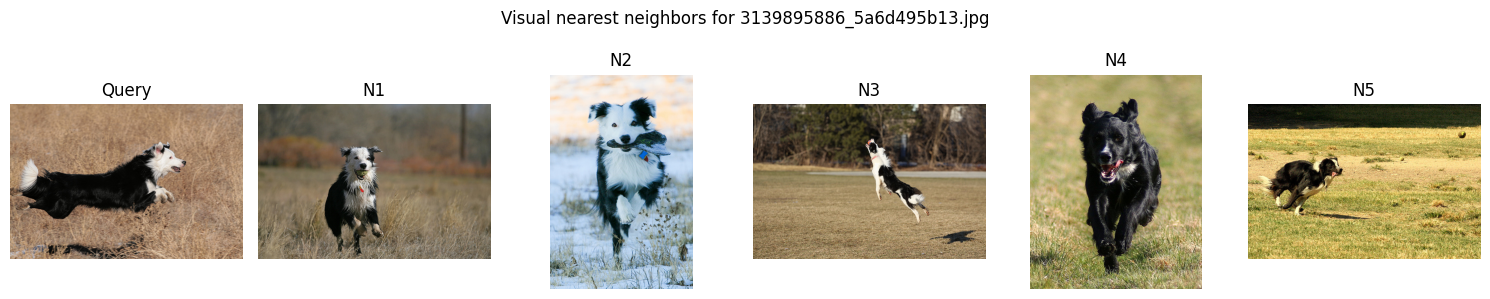

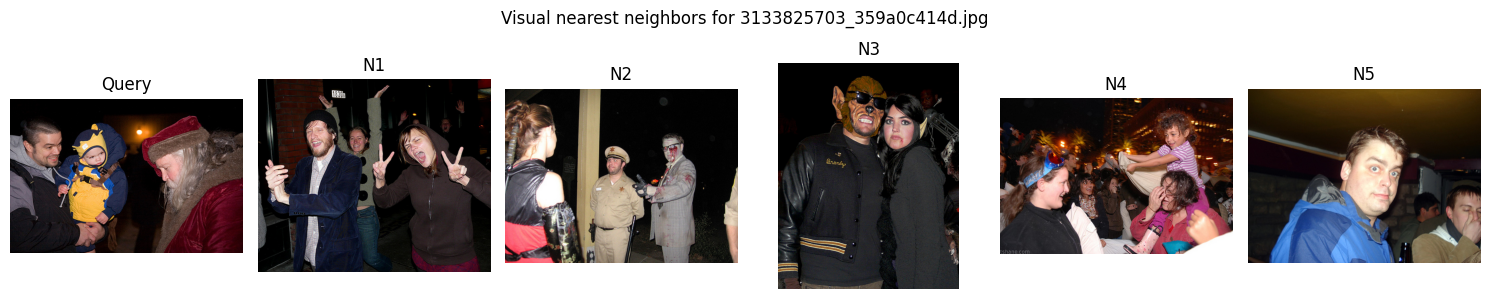

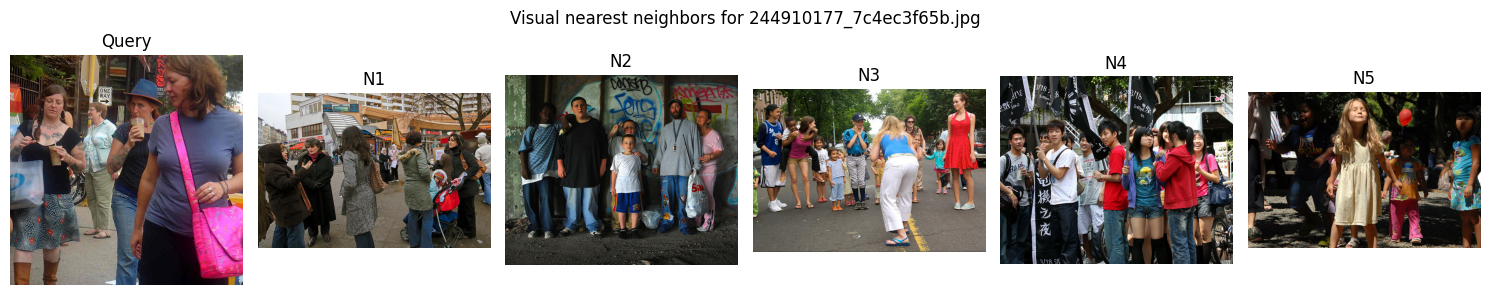

In [39]:
# show image neighbors
def show_image_neighbors(query_idx, neighbor_indices, save_path=None):
    selected_indices = [query_idx] + list(neighbor_indices)
    
    plt.figure(figsize=(15, 3))
    
    for i, idx in enumerate(selected_indices):
        img_name = image_names[idx]
        img_path = IMAGES_DIR / img_name
        
        with Image.open(img_path) as img:
            plt.subplot(1, len(selected_indices), i + 1)
            plt.imshow(img)
            plt.axis("off")
            
            if i == 0:
                plt.title("Query")
            else:
                plt.title(f"N{i}")
    
    plt.suptitle(f"Visual nearest neighbors for {image_names[query_idx]}")
    plt.tight_layout()
    
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    
    plt.show()

for count, idx in enumerate(sample_indices[:3], start=1):
    save_path = FIGURES_DIR / f"10_visual_neighbors_sample_{count}.png"
    show_image_neighbors(
        query_idx=idx,
        neighbor_indices=image_indices[idx][1:6],
        save_path=save_path
    )

In [40]:
# Cross-modal neighbor consistency

K = 5
overlap_rows = []

for i in range(len(image_names)):
    visual_neighbors = set(image_indices[i][1:K+1])
    text_neighbors = set(text_indices[i][1:K+1])
    
    overlap = visual_neighbors.intersection(text_neighbors)
    
    overlap_rows.append({
        "image": image_names[i],
        "visual_text_neighbor_overlap": len(overlap),
        "overlap_ratio": len(overlap) / K
    })

cross_modal_consistency_df = pd.DataFrame(overlap_rows)

display(cross_modal_consistency_df.describe())

cross_modal_summary_df = pd.DataFrame({
    "Metric": [
        "Mean visual-text top-5 neighbor overlap",
        "Median visual-text top-5 neighbor overlap",
        "Maximum visual-text top-5 neighbor overlap",
        "Mean overlap ratio"
    ],
    "Value": [
        cross_modal_consistency_df["visual_text_neighbor_overlap"].mean(),
        cross_modal_consistency_df["visual_text_neighbor_overlap"].median(),
        cross_modal_consistency_df["visual_text_neighbor_overlap"].max(),
        cross_modal_consistency_df["overlap_ratio"].mean()
    ]
})

display(cross_modal_summary_df)

cross_modal_consistency_df.to_csv(
    TABLES_DIR / "25_cross_modal_neighbor_consistency_all_images.csv",
    index=False
)

cross_modal_summary_df.to_csv(
    TABLES_DIR / "26_cross_modal_neighbor_consistency_summary.csv",
    index=False
)

,visual_text_neighbor_overlap,overlap_ratio
count,8091.000000,8091.000000
mean,0.310345,0.062069
std,0.614988,0.122998
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.000000,0.000000
max,5.000000,1.000000


,Metric,Value
0,Mean visual-text top-5 neighbor overlap,0.310345
1,Median visual-text top-5 neighbor overlap,0.000000
2,Maximum visual-text top-5 neighbor overlap,5.000000
3,Mean overlap ratio,0.062069


In [41]:
# Compare visual and text neighbors for sample images
neighbor_comparison_rows = []

for idx in sample_indices:
    visual_neighbor_names = [image_names[j] for j in image_indices[idx][1:K+1]]
    text_neighbor_names = [image_names[j] for j in text_indices[idx][1:K+1]]
    
    overlap_names = sorted(
        list(set(visual_neighbor_names).intersection(set(text_neighbor_names)))
    )
    
    neighbor_comparison_rows.append({
        "query_image": image_names[idx],
        "query_caption_sample": captions_df[captions_df["image"] == image_names[idx]]["caption"].iloc[0],
        "visual_neighbors": ", ".join(visual_neighbor_names),
        "text_neighbors": ", ".join(text_neighbor_names),
        "overlap_count": len(overlap_names),
        "overlap_images": ", ".join(overlap_names)
    })

neighbor_comparison_df = pd.DataFrame(neighbor_comparison_rows)

display(neighbor_comparison_df)

neighbor_comparison_df.to_csv(
    TABLES_DIR / "27_visual_vs_text_neighbor_examples.csv",
    index=False
)

,query_image,query_caption_sample,visual_neighbors,text_neighbors,overlap_count,overlap_images
0,3139895886_5a6d495b13.jpg,"A black-and-white dog bounds off the ground , ...","3025546819_ce031d2fc3.jpg, 3239480519_22540b50...","2084103826_ffd76b1e3e.jpg, 2792409624_2731b107...",0,
1,3133825703_359a0c414d.jpg,A child staring at Santa .,"3004287781_c041c09c16.jpg, 2991994607_06f24ec7...","2622517932_57c52c376f.jpg, 1244485675_822e6efe...",0,
2,244910177_7c4ec3f65b.jpg,Three woman walk down a city street and one ha...,"3336211088_4c294a870b.jpg, 3582814058_564776f2...","1776981714_5b224d0f7a.jpg, 2695001634_127fe2f0...",0,
3,2127207912_9298824e66.jpg,"The two people are standing on a rock , holdin...","765929807_de381cc764.jpg, 1478268555_7e301fc51...","405534993_5158644f98.jpg, 508958120_afe274f726...",0,
4,1810651611_35aae644fb.jpg,A closeup of a little girl on a swing .,"2609900643_c07bcb0bae.jpg, 3452411712_5b42d2a1...","1682079482_9a72fa57fa.jpg, 1561658940_a947f244...",0,


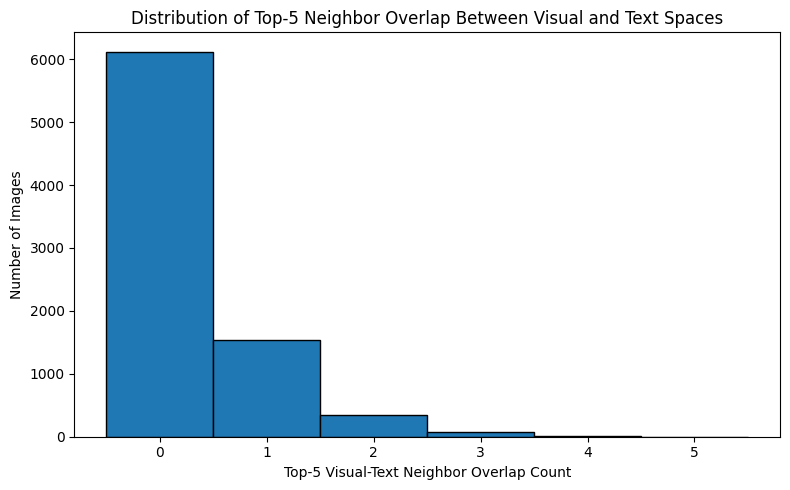

In [42]:
# Distribution of visual-text neighbor overlap

plt.figure(figsize=(8, 5))
plt.hist(
    cross_modal_consistency_df["visual_text_neighbor_overlap"],
    bins=np.arange(-0.5, 6.5, 1),
    edgecolor="black"
)
plt.xlabel("Top-5 Visual-Text Neighbor Overlap Count")
plt.ylabel("Number of Images")
plt.title("Distribution of Top-5 Neighbor Overlap Between Visual and Text Spaces")
plt.xticks(range(0, 6))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_visual_text_neighbor_overlap_distribution.png", dpi=300)
plt.show()

In [43]:
# Examples with highest visual-text neighbor overlap

top_overlap_examples = (
    cross_modal_consistency_df
    .sort_values("visual_text_neighbor_overlap", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_overlap_examples)

top_overlap_examples.to_csv(
    TABLES_DIR / "28_highest_visual_text_overlap_examples.csv",
    index=False
)

,image,visual_text_neighbor_overlap,overlap_ratio
0,1807169176_7f5226bf5a.jpg,5,1.0
1,2848977044_446a31d86e.jpg,4,0.8
2,143552829_72b6ba49d4.jpg,4,0.8
3,2461631708_decc5b8c87.jpg,4,0.8
4,1433397131_8634fa6664.jpg,4,0.8
5,2460797929_66446c13db.jpg,4,0.8
6,3312096605_f458757418.jpg,4,0.8
7,3516312179_f520469038.jpg,4,0.8
8,3517124784_4b4eb62a7a.jpg,4,0.8
9,3677514746_26f5588150.jpg,4,0.8


In [44]:
# Detailed high-overlap examples

high_overlap_rows = []

for img_name in top_overlap_examples["image"].head(5):
    idx = image_names.index(img_name)
    
    visual_neighbor_names = [image_names[j] for j in image_indices[idx][1:K+1]]
    text_neighbor_names = [image_names[j] for j in text_indices[idx][1:K+1]]
    overlap_names = sorted(list(set(visual_neighbor_names).intersection(set(text_neighbor_names))))
    
    high_overlap_rows.append({
        "query_image": img_name,
        "query_caption_sample": captions_df[captions_df["image"] == img_name]["caption"].iloc[0],
        "visual_neighbors": ", ".join(visual_neighbor_names),
        "text_neighbors": ", ".join(text_neighbor_names),
        "overlap_count": len(overlap_names),
        "overlap_images": ", ".join(overlap_names)
    })

high_overlap_detail_df = pd.DataFrame(high_overlap_rows)

display(high_overlap_detail_df)

high_overlap_detail_df.to_csv(
    TABLES_DIR / "29_high_overlap_visual_text_neighbor_details.csv",
    index=False
)

,query_image,query_caption_sample,visual_neighbors,text_neighbors,overlap_count,overlap_images
0,1807169176_7f5226bf5a.jpg,A group of people sit around a blazing fire at...,"3070274658_fc39fd4f84.jpg, 2610447973_89227ff9...","69710411_2cf537f61f.jpg, 3138746531_f6b816c126...",5,"2610447973_89227ff978.jpg, 3070274658_fc39fd4f..."
1,2848977044_446a31d86e.jpg,A cowboy is hanging upside down from a horse .,"3568505408_4e30def669.jpg, 2656987333_80dcc82c...","2656987333_80dcc82c05.jpg, 3568505408_4e30def6...",4,"2656987333_80dcc82c05.jpg, 3319489465_c65c91e4..."
2,143552829_72b6ba49d4.jpg,A boy in a black helmet and red long sleeve sh...,"152029243_b3582c36fa.jpg, 479807833_85eed6899c...","152029243_b3582c36fa.jpg, 3609032038_005c789f6...",4,"152029243_b3582c36fa.jpg, 216172386_9ac5356dae..."
3,2461631708_decc5b8c87.jpg,kids in orange life vests on sitting in a blac...,"2460799229_ce45a1d940.jpg, 2460797929_66446c13...","2460799229_ce45a1d940.jpg, 2460797929_66446c13...",4,"2460797929_66446c13db.jpg, 2460799229_ce45a1d9..."
4,1433397131_8634fa6664.jpg,A baby lies almost completely covered by brigh...,"2265100168_175f8218af.jpg, 2279980395_989d48ae...","2279980395_989d48ae72.jpg, 820169182_f5e78d7d1...",4,"2265100168_175f8218af.jpg, 2279980395_989d48ae..."


In [45]:
#model2--------------------------------------------------------------------------------

In [46]:
# Reduce image embeddings to 256 dimensions for matching

from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
import joblib

image_to_idx = {img: i for i, img in enumerate(image_names)}

train_image_names = sorted(train_df["image"].unique())
val_image_names = sorted(val_df["image"].unique())
test_image_names = sorted(test_df["image"].unique())

train_img_indices = [image_to_idx[img] for img in train_image_names]

# normalize original ResNet features first
X_image_norm = normalize(X_image_resnet)

pca_image = PCA(n_components=256, random_state=42)
pca_image.fit(X_image_norm[train_img_indices])

X_image_pca = pca_image.transform(X_image_norm)
X_image_pca = normalize(X_image_pca)

print("Reduced image embedding shape:", X_image_pca.shape)
print("Image PCA explained variance:", pca_image.explained_variance_ratio_.sum())

np.save(CACHE_DIR / "image_embeddings_resnet50_pca256.npy", X_image_pca)
joblib.dump(pca_image, CACHE_DIR / "pca_image_model.joblib")

Reduced image embedding shape: (8091, 256)
Image PCA explained variance: 0.7701061


['F:\\homeworks\\data analysis\\Flickr8k-Multimodal-NLP\\cache\\pca_image_model.joblib']

In [47]:
# Build image-caption matching pairs

SEED = 42
rng = np.random.default_rng(SEED)

def build_matching_pairs(split_image_names, n_negatives=1):
    X_pairs = []
    y_pairs = []
    pair_rows = []
    
    split_indices = [image_to_idx[img] for img in split_image_names]
    
    for img_name in split_image_names:
        img_idx = image_to_idx[img_name]
        
        img_vec = X_image_pca[img_idx]
        true_text_vec = X_text_svd[img_idx]
        
        # positive pair
        pair_feature = np.concatenate([
            img_vec,
            true_text_vec,
            np.abs(img_vec - true_text_vec),
            img_vec * true_text_vec
        ])
        
        X_pairs.append(pair_feature)
        y_pairs.append(1)
        pair_rows.append({
            "image": img_name,
            "text_image": img_name,
            "label": 1
        })
        
        # negative pair(s)
        for _ in range(n_negatives):
            neg_idx = img_idx
            
            while neg_idx == img_idx:
                neg_idx = rng.choice(split_indices)
            
            neg_text_vec = X_text_svd[neg_idx]
            neg_text_image = image_names[neg_idx]
            
            pair_feature = np.concatenate([
                img_vec,
                neg_text_vec,
                np.abs(img_vec - neg_text_vec),
                img_vec * neg_text_vec
            ])
            
            X_pairs.append(pair_feature)
            y_pairs.append(0)
            pair_rows.append({
                "image": img_name,
                "text_image": neg_text_image,
                "label": 0
            })
    
    X_pairs = np.vstack(X_pairs)
    y_pairs = np.array(y_pairs)
    pair_df = pd.DataFrame(pair_rows)
    
    return X_pairs, y_pairs, pair_df

X_train_match, y_train_match, train_pairs_df = build_matching_pairs(train_image_names, n_negatives=1)
X_val_match, y_val_match, val_pairs_df = build_matching_pairs(val_image_names, n_negatives=1)
X_test_match, y_test_match, test_pairs_df = build_matching_pairs(test_image_names, n_negatives=1)

print("Train pairs:", X_train_match.shape, y_train_match.shape)
print("Validation pairs:", X_val_match.shape, y_val_match.shape)
print("Test pairs:", X_test_match.shape, y_test_match.shape)

display(train_pairs_df["label"].value_counts())
display(test_pairs_df["label"].value_counts())

train_pairs_df.to_csv(TABLES_DIR / "30_train_matching_pairs.csv", index=False)
val_pairs_df.to_csv(TABLES_DIR / "31_val_matching_pairs.csv", index=False)
test_pairs_df.to_csv(TABLES_DIR / "32_test_matching_pairs.csv", index=False)

Train pairs: (11326, 1024) (11326,)
Validation pairs: (2428, 1024) (2428,)
Test pairs: (2428, 1024) (2428,)


label
1    5663
0    5663
Name: count, dtype: int64

label
1    1214
0    1214
Name: count, dtype: int64

In [48]:
# Train image-caption matching classifier

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

matching_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight="balanced"
    ))
])

matching_model.fit(X_train_match, y_train_match)

print("Matching model trained.")

Matching model trained.


,threshold,accuracy,balanced_accuracy,precision,recall,f1_score
21,0.31,0.710049,0.710049,0.648775,0.915980,0.759563
22,0.32,0.711285,0.711285,0.650971,0.911038,0.759355
19,0.29,0.705519,0.705519,0.642653,0.925865,0.758691
20,0.30,0.706755,0.706755,0.644919,0.920099,0.758316
17,0.27,0.701400,0.701400,0.637282,0.934926,0.757930
16,0.26,0.699341,0.699341,0.634444,0.940692,0.757797
15,0.25,0.696870,0.696870,0.631175,0.947282,0.757576
18,0.28,0.702636,0.702636,0.639614,0.928336,0.757392
23,0.33,0.710461,0.710461,0.652355,0.901153,0.756832
27,0.37,0.719110,0.719110,0.667506,0.873147,0.756602


Best threshold based on validation F1: 0.30999999999999994


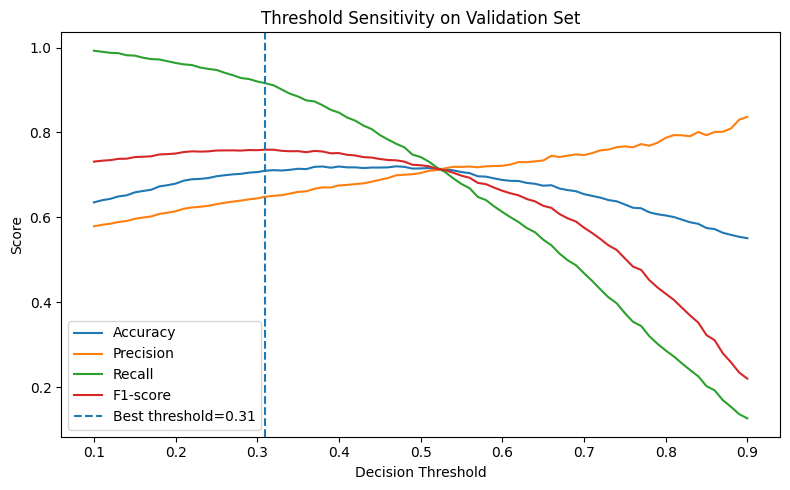

In [49]:
# Threshold analysis for image-caption matching

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

y_val_proba = matching_model.predict_proba(X_val_match)[:, 1]
y_test_proba = matching_model.predict_proba(X_test_match)[:, 1]

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_rows = []

for th in thresholds:
    y_val_pred_th = (y_val_proba >= th).astype(int)
    
    threshold_rows.append({
        "threshold": th,
        "accuracy": accuracy_score(y_val_match, y_val_pred_th),
        "balanced_accuracy": balanced_accuracy_score(y_val_match, y_val_pred_th),
        "precision": precision_score(y_val_match, y_val_pred_th),
        "recall": recall_score(y_val_match, y_val_pred_th),
        "f1_score": f1_score(y_val_match, y_val_pred_th)
    })

threshold_df = pd.DataFrame(threshold_rows)

display(threshold_df.sort_values("f1_score", ascending=False).head(10))

best_threshold = threshold_df.loc[threshold_df["f1_score"].idxmax(), "threshold"]

print("Best threshold based on validation F1:", best_threshold)

threshold_df.to_csv(
    TABLES_DIR / "34_matching_threshold_analysis_validation.csv",
    index=False
)

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["accuracy"], label="Accuracy")
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1_score"], label="F1-score")
plt.axvline(best_threshold, linestyle="--", label=f"Best threshold={best_threshold:.2f}")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Sensitivity on Validation Set")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "13_matching_threshold_sensitivity.png", dpi=300)
plt.show()

Validation
              precision    recall  f1-score   support

  Mismatched       0.73      0.69      0.71      1214
     Matched       0.70      0.74      0.72      1214

    accuracy                           0.72      2428
   macro avg       0.72      0.72      0.72      2428
weighted avg       0.72      0.72      0.72      2428



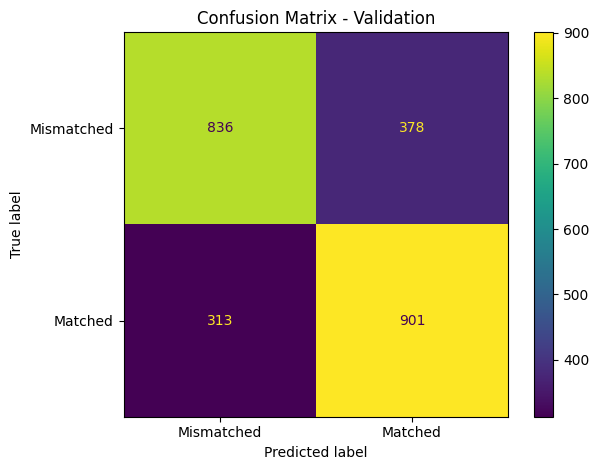

Test
              precision    recall  f1-score   support

  Mismatched       0.73      0.66      0.69      1214
     Matched       0.69      0.75      0.72      1214

    accuracy                           0.71      2428
   macro avg       0.71      0.71      0.71      2428
weighted avg       0.71      0.71      0.71      2428



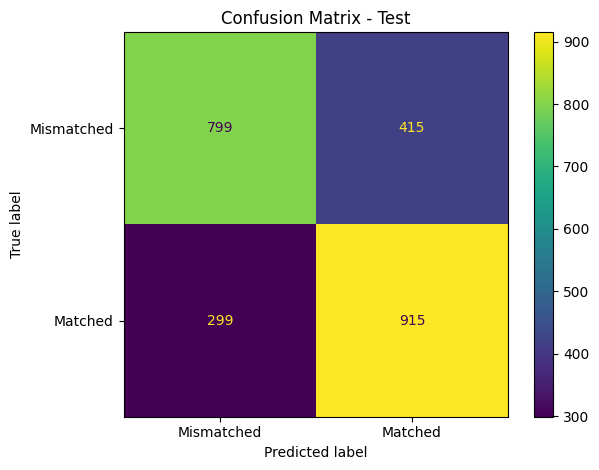

,split,accuracy,precision,recall,f1_score,roc_auc
0,Validation,0.715404,0.704457,0.742175,0.722824,0.786981
1,Test,0.705931,0.687970,0.753707,0.719340,0.776588


In [50]:
# Evaluate matching model with confusion matrix

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

def evaluate_matching_model(model, X, y, split_name):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    
    metrics = {
        "split": split_name,
        "accuracy": accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred),
        "recall": recall_score(y, y_pred),
        "f1_score": f1_score(y, y_pred),
        "roc_auc": roc_auc_score(y, y_proba)
    }
    
    print("=" * 80)
    print(split_name)
    print(classification_report(y, y_pred, target_names=["Mismatched", "Matched"]))
    
    cm = confusion_matrix(y, y_pred)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Mismatched", "Matched"]
    )
    
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix - {split_name}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"12_confusion_matrix_matching_{split_name.lower()}.png", dpi=300)
    plt.show()
    
    return metrics, cm

val_metrics, val_cm = evaluate_matching_model(matching_model, X_val_match, y_val_match, "Validation")
test_metrics, test_cm = evaluate_matching_model(matching_model, X_test_match, y_test_match, "Test")

matching_metrics_df = pd.DataFrame([val_metrics, test_metrics])
display(matching_metrics_df)

matching_metrics_df.to_csv(
    TABLES_DIR / "33_image_caption_matching_metrics.csv",
    index=False
)

np.save(CACHE_DIR / "matching_test_confusion_matrix.npy", test_cm)

Test with threshold = 0.31
              precision    recall  f1-score   support

  Mismatched       0.85      0.48      0.62      1214
     Matched       0.64      0.92      0.75      1214

    accuracy                           0.70      2428
   macro avg       0.75      0.70      0.68      2428
weighted avg       0.75      0.70      0.68      2428



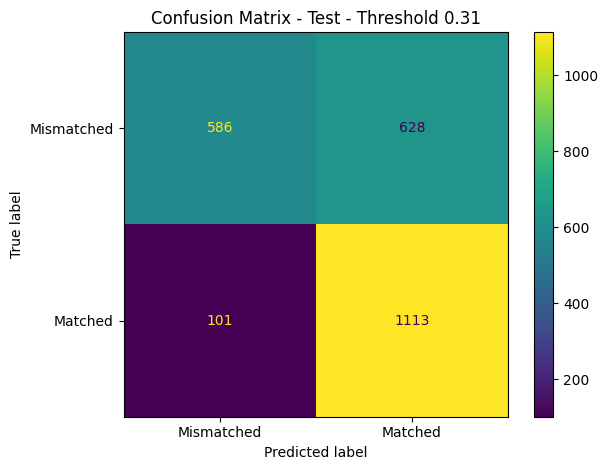

,split,threshold,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc
0,Test,0.31,0.699753,0.699753,0.639288,0.916804,0.753299,0.776588


In [51]:
# Evaluate matching model on test set using selected threshold

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def evaluate_with_threshold(y_true, y_proba, threshold, split_name):
    y_pred = (y_proba >= threshold).astype(int)
    
    metrics = {
        "split": split_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1_score": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_proba)
    }
    
    print("=" * 80)
    print(f"{split_name} with threshold = {threshold:.2f}")
    print(classification_report(y_true, y_pred, target_names=["Mismatched", "Matched"]))
    
    cm = confusion_matrix(y_true, y_pred)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Mismatched", "Matched"]
    )
    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix - {split_name} - Threshold {threshold:.2f}")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"14_confusion_matrix_matching_{split_name.lower()}_threshold_{threshold:.2f}.png", dpi=300)
    plt.show()
    
    return metrics, cm, y_pred

test_metrics_tuned, test_cm_tuned, y_test_pred_tuned = evaluate_with_threshold(
    y_test_match,
    y_test_proba,
    best_threshold,
    "Test"
)

test_metrics_tuned_df = pd.DataFrame([test_metrics_tuned])
display(test_metrics_tuned_df)

test_metrics_tuned_df.to_csv(
    TABLES_DIR / "35_matching_test_metrics_tuned_threshold.csv",
    index=False
)

np.save(CACHE_DIR / "matching_test_confusion_matrix_tuned.npy", test_cm_tuned)

In [52]:
# Save trained image-caption matching model
import joblib

joblib.dump(matching_model, CACHE_DIR / "image_caption_matching_logistic_regression.joblib")

print("Matching model saved.")

Matching model saved.


Device: cuda
Input image: F:\homeworks\data analysis\Flickr8k-Multimodal-NLP\dataset\Images\1089181217_ee1167f7af.jpg
Original caption: A brown dog running next to grass .
Cleaned caption: a brown dog running next to grass
Match probability: 0.8080
Prediction: Matched


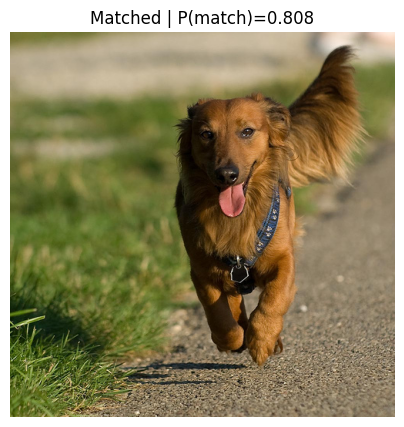

{'image_path': 'F:\\homeworks\\data analysis\\Flickr8k-Multimodal-NLP\\dataset\\Images\\1089181217_ee1167f7af.jpg',
 'caption': 'A brown dog running next to grass .',
 'clean_caption': 'a brown dog running next to grass',
 'match_probability': np.float64(0.807992437250857),
 'prediction': 'Matched'}

In [53]:
# Build prediction function for a custom image-caption pair

import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
from pathlib import Path
import re
import numpy as np
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ResNet50 feature extractor for external images
weights = ResNet50_Weights.DEFAULT
preprocess = weights.transforms()

resnet_query = resnet50(weights=weights)
feature_extractor_query = nn.Sequential(*list(resnet_query.children())[:-1])
feature_extractor_query = feature_extractor_query.to(device)
feature_extractor_query.eval()


def clean_query_caption(text):
    """
    Clean a user-provided caption using the same basic logic used in EDA.
    """
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def extract_query_image_embedding(image_path):
    """
    Convert one external image into the same 256-dimensional visual embedding
    used by the matching model.
    """
    image_path = Path(image_path)
    
    image = Image.open(image_path).convert("RGB")
    image_tensor = preprocess(image).unsqueeze(0).to(device)
    
    with torch.inference_mode():
        feature = feature_extractor_query(image_tensor)
        feature = feature.view(feature.size(0), -1)
    
    image_resnet = feature.cpu().numpy()          # shape: (1, 2048)
    image_resnet_norm = normalize(image_resnet)   # same normalization used before PCA
    
    image_pca = pca_image.transform(image_resnet_norm)  # shape: (1, 256)
    image_pca = normalize(image_pca)
    
    return image_pca


def extract_query_text_embedding(caption):
    """
    Convert one external caption into the same 256-dimensional text embedding
    used by the matching model.
    """
    clean_caption = clean_query_caption(caption)
    
    caption_tfidf = tfidf_vectorizer.transform([clean_caption])
    caption_svd = svd_text.transform(caption_tfidf)
    caption_svd = normalize(caption_svd)
    
    return caption_svd, clean_caption


def build_pair_feature_from_embeddings(img_vec, text_vec):
    """
    Build the same pair feature used during model training:
    [v, t, |v - t|, v * t]
    """
    pair_feature = np.concatenate([
        img_vec[0],
        text_vec[0],
        np.abs(img_vec[0] - text_vec[0]),
        img_vec[0] * text_vec[0]
    ])
    
    return pair_feature.reshape(1, -1)


def predict_image_caption_match(image_path, caption, threshold=0.31, show_image=True):
    """
    Predict whether a given image and caption match.
    """
    img_vec = extract_query_image_embedding(image_path)
    text_vec, clean_caption = extract_query_text_embedding(caption)
    
    pair_feature = build_pair_feature_from_embeddings(img_vec, text_vec)
    
    match_probability = matching_model.predict_proba(pair_feature)[0, 1]
    predicted_label = int(match_probability >= threshold)
    
    if predicted_label == 1:
        prediction_text = "Matched"
    else:
        prediction_text = "Mismatched"
    
    print("=" * 100)
    print("Input image:", image_path)
    print("Original caption:", caption)
    print("Cleaned caption:", clean_caption)
    print(f"Match probability: {match_probability:.4f}")
    print("Prediction:", prediction_text)
    
    if show_image:
        img = Image.open(image_path).convert("RGB")
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{prediction_text} | P(match)={match_probability:.3f}")
        plt.show()
    
    return {
        "image_path": str(image_path),
        "caption": caption,
        "clean_caption": clean_caption,
        "match_probability": match_probability,
        "prediction": prediction_text
    }
    
custom_image_path = IMAGES_DIR / "1089181217_ee1167f7af.jpg"

custom_caption = "A brown dog running next to grass ."

custom_result = predict_image_caption_match(
    image_path=custom_image_path,
    caption=custom_caption,
    threshold=0.5,
    show_image=True
)

custom_result

In [54]:
# Error analysis for image-caption matching using tuned threshold

try:
    y_test_pred_for_error = y_test_pred_tuned
except NameError:
    y_test_proba = matching_model.predict_proba(X_test_match)[:, 1]
    y_test_pred_for_error = (y_test_proba >= best_threshold).astype(int)

test_error_df = test_pairs_df.copy()
test_error_df["true_label"] = y_test_match
test_error_df["predicted_label"] = y_test_pred_for_error
test_error_df["match_probability"] = y_test_proba

false_positive_df = test_error_df[
    (test_error_df["true_label"] == 0) &
    (test_error_df["predicted_label"] == 1)
].sort_values("match_probability", ascending=False)

false_negative_df = test_error_df[
    (test_error_df["true_label"] == 1) &
    (test_error_df["predicted_label"] == 0)
].sort_values("match_probability", ascending=True)

print("False positives:", len(false_positive_df))
print("False negatives:", len(false_negative_df))

display(false_positive_df.head(5))
display(false_negative_df.head(5))

false_positive_df.to_csv(TABLES_DIR / "36_matching_false_positive_examples.csv", index=False)
false_negative_df.to_csv(TABLES_DIR / "37_matching_false_negative_examples.csv", index=False)

False positives: 628
False negatives: 101


,image,text_image,label,true_label,predicted_label,match_probability
413,2196846255_2c1635359a.jpg,2340919359_f56787d307.jpg,0,0,1,0.994504
1199,3041487045_b48ac7ed08.jpg,2303016989_0deb96c8d9.jpg,0,0,1,0.990041
969,2800990525_a1f8427272.jpg,3470008804_0ca36a7a09.jpg,0,0,1,0.986986
1041,2867845624_22e4fe0a23.jpg,1526325728_74eb4153d8.jpg,0,0,1,0.977520
2229,467960888_6943257534.jpg,3455757720_7aeba57056.jpg,0,0,1,0.976140


,image,text_image,label,true_label,predicted_label,match_probability
626,241347635_e691395c2f.jpg,241347635_e691395c2f.jpg,1,1,0,0.023076
1304,3123770450_cedc16d162.jpg,3123770450_cedc16d162.jpg,1,1,0,0.030283
2084,3683592946_262e9bfbfd.jpg,3683592946_262e9bfbfd.jpg,1,1,0,0.030331
1220,3056569684_c264c88d00.jpg,3056569684_c264c88d00.jpg,1,1,0,0.038163
542,2337809114_899ba61330.jpg,2337809114_899ba61330.jpg,1,1,0,0.042220


In [55]:
# readable error examples

def print_matching_error_examples(error_df, title, n=2):
    print("=" * 100)
    print(title)

    for _, row in error_df.head(n).iterrows():
        image_name = row["image"]
        text_image_name = row["text_image"]

        image_caps = captions_df[captions_df["image"] == image_name]["caption"].tolist()
        text_caps = captions_df[captions_df["image"] == text_image_name]["caption"].tolist()

        print("-" * 100)
        print("Image:", image_name)
        print("Text taken from image:", text_image_name)
        print("True label:", row["true_label"])
        print("Predicted label:", row["predicted_label"])
        print("Match probability:", row["match_probability"])

        print("\nActual image captions:")
        for cap in image_caps[:3]:
            print("  -", cap)

        print("\nCandidate text captions:")
        for cap in text_caps[:3]:
            print("  -", cap)

print_matching_error_examples(false_positive_df, "False Positive Examples", n=2)
print_matching_error_examples(false_negative_df, "False Negative Examples", n=2)

False Positive Examples
----------------------------------------------------------------------------------------------------
Image: 2196846255_2c1635359a.jpg
Text taken from image: 2340919359_f56787d307.jpg
True label: 0
Predicted label: 1
Match probability: 0.9945042507485446

Actual image captions:
  - A dog standing in the shallow part of the ocean while the waves splash around .
  - A dog standing in the water .
  - A wrinkled dog wading in shallow water .

Candidate text captions:
  - A man is sitting on a black and brown dog .
  - A man stands over a brown and black dog in the grass .
  - a man wearing a black and white shirt jumping on a dog 's back
----------------------------------------------------------------------------------------------------
Image: 3041487045_b48ac7ed08.jpg
Text taken from image: 2303016989_0deb96c8d9.jpg
True label: 0
Predicted label: 1
Match probability: 0.9900410306484068

Actual image captions:
  - A dog runs through the woods .
  - A pale tan dog rom

In [56]:
# Final summary for Model 2: Image-Caption Matching

model2_summary_df = pd.DataFrame({
    "Item": [
        "Task",
        "Positive pair definition",
        "Negative pair definition",
        "Image representation",
        "Text representation",
        "Pair feature",
        "Classifier",
        "Selected threshold",
        "Threshold selection criterion",
        "Test accuracy",
        "Test precision for Matched",
        "Test recall for Matched",
        "Test F1 for Matched",
        "Test ROC-AUC",
        "False positives",
        "False negatives",
        "Main limitation"
    ],
    "Value": [
        "Binary image-caption matching",
        "Image with its own combined captions",
        "Image with captions from another image",
        "ResNet50 embedding reduced to 256 dimensions with PCA",
        "TF-IDF reduced to 256 dimensions with SVD",
        "[v, t, |v - t|, v * t]",
        "Logistic Regression",
        "0.31",
        "Best validation F1-score",
        0.699753,
        0.639288,
        0.916804,
        0.753299,
        0.776588,
        628,
        101,
        "The model often treats semantically similar but incorrect captions as matched."
    ]
})

display(model2_summary_df)

model2_summary_df.to_csv(
    TABLES_DIR / "38_model2_final_summary.csv",
    index=False
)

,Item,Value
0,Task,Binary image-caption matching
1,Positive pair definition,Image with its own combined captions
2,Negative pair definition,Image with captions from another image
3,Image representation,ResNet50 embedding reduced to 256 dimensions w...
4,Text representation,TF-IDF reduced to 256 dimensions with SVD
5,Pair feature,"[v, t, |v - t|, v * t]"
6,Classifier,Logistic Regression
7,Selected threshold,0.31
8,Threshold selection criterion,Best validation F1-score
9,Test accuracy,0.699753


In [57]:
#model3---------------------------------------------------------------------------------------

In [58]:
# Build vocabulary for caption generation
# Uses previous EDA decisions:
# - MIN_FREQ = 5
# - stopwords are NOT removed for caption generation
# - vocabulary is built only from train_df to avoid leakage

from collections import Counter
import json
import numpy as np
import pandas as pd

if "clean_caption" not in train_df.columns:
    train_df["clean_caption"] = train_df["caption"].apply(clean_caption_for_eda)

if "clean_caption" not in val_df.columns:
    val_df["clean_caption"] = val_df["caption"].apply(clean_caption_for_eda)

if "clean_caption" not in test_df.columns:
    test_df["clean_caption"] = test_df["caption"].apply(clean_caption_for_eda)

PAD_TOKEN = "<pad>"
START_TOKEN = "<start>"
END_TOKEN = "<end>"
UNK_TOKEN = "<unk>"

MIN_FREQ = 5

word_counter = Counter()

for cap in train_df["clean_caption"]:
    word_counter.update(cap.split())

special_tokens = [PAD_TOKEN, START_TOKEN, END_TOKEN, UNK_TOKEN]

vocab_words = [
    word for word, freq in word_counter.items()
    if freq >= MIN_FREQ
]

idx2word = special_tokens + sorted(vocab_words)
word2idx = {word: idx for idx, word in enumerate(idx2word)}

PAD_IDX = word2idx[PAD_TOKEN]
START_IDX = word2idx[START_TOKEN]
END_IDX = word2idx[END_TOKEN]
UNK_IDX = word2idx[UNK_TOKEN]

print("Vocabulary size:", len(word2idx))
print("MIN_FREQ:", MIN_FREQ)
print("PAD_IDX:", PAD_IDX)
print("START_IDX:", START_IDX)
print("END_IDX:", END_IDX)
print("UNK_IDX:", UNK_IDX)

Vocabulary size: 2482
MIN_FREQ: 5
PAD_IDX: 0
START_IDX: 1
END_IDX: 2
UNK_IDX: 3


In [59]:
# Select maximum caption length for sequence modeling

train_caption_lengths = train_df["clean_caption"].apply(lambda x: len(x.split()) + 2)

caption_length_for_model_df = train_caption_lengths.describe().to_frame(name="caption_length_with_start_end")

display(caption_length_for_model_df)

p95_len = int(np.percentile(train_caption_lengths, 95))
p99_len = int(np.percentile(train_caption_lengths, 99))

print("95th percentile length:", p95_len)
print("99th percentile length:", p99_len)

# 95th percentile, to avoid very rare lengths and extra cost
MAX_LEN = max(p95_len, 10)

print("Selected MAX_LEN:", MAX_LEN)

caption_length_for_model_df.to_csv(
    TABLES_DIR / "39_caption_length_for_model_train_only.csv"
)

,caption_length_with_start_end
count,28315.000000
mean,12.802861
std,3.772714
min,3.000000
25%,10.000000
50%,12.000000
75%,15.000000
max,38.000000


95th percentile length: 20
99th percentile length: 24
Selected MAX_LEN: 20


In [60]:
# Save caption generation preprocessing decisions

caption_generation_preprocessing_df = pd.DataFrame({
    "Component": [
        "Caption unit",
        "Text cleaning",
        "Stopword removal",
        "Vocabulary source",
        "Rare word threshold",
        "Special tokens",
        "Maximum sequence length",
        "Image representation"
    ],
    "Decision": [
        "Each image-caption row is treated as one training sample.",
        "Lowercasing and punctuation removal using clean_caption.",
        "No stopword removal is applied.",
        "Vocabulary is built only from training captions.",
        f"Words with train frequency < {MIN_FREQ} are mapped to <unk>.",
        "<pad>, <start>, <end>, <unk>",
        f"MAX_LEN = {MAX_LEN}",
        "Cached ResNet50 2048-dimensional image embeddings."
    ],
    "Justification": [
        "Each image has five valid human captions; treating them separately increases supervised training examples.",
        "This standardizes tokens while preserving grammatical words.",
        "Stopwords are needed for grammatical caption generation.",
        "Using only train captions avoids vocabulary leakage from validation/test.",
        "The earlier EDA showed that min_freq=5 preserves most tokens while reducing rare-word sparsity.",
        "Special tokens are required for sequence padding, generation start, generation stop, and unknown words.",
        "The selected length covers most training captions while controlling computational cost.",
        "ResNet50 features were already extracted and avoid retraining a CNN from scratch."
    ]
})

display(caption_generation_preprocessing_df)

caption_generation_preprocessing_df.to_csv(
    TABLES_DIR / "40_caption_generation_preprocessing_decisions.csv",
    index=False
)

,Component,Decision,Justification
0,Caption unit,Each image-caption row is treated as one train...,Each image has five valid human captions; trea...
1,Text cleaning,Lowercasing and punctuation removal using clea...,This standardizes tokens while preserving gram...
2,Stopword removal,No stopword removal is applied.,Stopwords are needed for grammatical caption g...
3,Vocabulary source,Vocabulary is built only from training captions.,Using only train captions avoids vocabulary le...
4,Rare word threshold,Words with train frequency < 5 are mapped to <...,The earlier EDA showed that min_freq=5 preserv...
5,Special tokens,"<pad>, <start>, <end>, <unk>",Special tokens are required for sequence paddi...
6,Maximum sequence length,MAX_LEN = 20,The selected length covers most training capti...
7,Image representation,Cached ResNet50 2048-dimensional image embeddi...,ResNet50 features were already extracted and a...


In [61]:
# Save caption vocabulary

vocab_info = {
    "min_freq": MIN_FREQ,
    "vocab_size": len(word2idx),
    "max_len": MAX_LEN,
    "pad_idx": PAD_IDX,
    "start_idx": START_IDX,
    "end_idx": END_IDX,
    "unk_idx": UNK_IDX,
    "word2idx": word2idx,
    "idx2word": idx2word
}

with open(CACHE_DIR / "caption_vocab.json", "w", encoding="utf-8") as f:
    json.dump(vocab_info, f, ensure_ascii=False, indent=2)

print("Vocabulary saved to:", CACHE_DIR / "caption_vocab.json")

Vocabulary saved to: F:\homeworks\data analysis\Flickr8k-Multimodal-NLP\cache\caption_vocab.json


In [62]:
# Caption encoding utilities

def encode_caption(caption, word2idx, max_len):
    tokens = [START_TOKEN] + str(caption).split() + [END_TOKEN]
    
    ids = [
        word2idx.get(token, UNK_IDX)
        for token in tokens
    ]
    
    if len(ids) > max_len:
        ids = ids[:max_len]
        ids[-1] = END_IDX
    
    # padding
    if len(ids) < max_len:
        ids = ids + [PAD_IDX] * (max_len - len(ids))
    
    return ids


sample_caption = train_df["clean_caption"].iloc[0]
sample_ids = encode_caption(sample_caption, word2idx, MAX_LEN)

print("Sample caption:", sample_caption)
print("Encoded ids:", sample_ids)
print("Decoded tokens:", [idx2word[i] for i in sample_ids])

Sample caption: a black dog and a spotted dog are fighting
Encoded ids: [1, 4, 214, 607, 43, 4, 2018, 607, 58, 746, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Decoded tokens: ['<start>', 'a', 'black', 'dog', 'and', 'a', 'spotted', 'dog', 'are', 'fighting', '<end>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>']


In [63]:
# PyTorch Dataset for caption generation

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import normalize

# use feature from ResNet50
X_caption_image_features = normalize(X_image_resnet).astype(np.float32)

class CaptionFeatureDataset(Dataset):
    def __init__(self, df, image_features, image_to_idx, word2idx, max_len):
        self.df = df.reset_index(drop=True)
        self.image_features = image_features
        self.image_to_idx = image_to_idx
        self.word2idx = word2idx
        self.max_len = max_len
    
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_name = row["image"]
        caption = row["clean_caption"]
        
        img_idx = self.image_to_idx[img_name]
        img_feature = self.image_features[img_idx]
        
        seq = encode_caption(caption, self.word2idx, self.max_len)
        
        input_ids = seq[:-1]   # <start> ... 
        target_ids = seq[1:]   # ... <end>
        
        return (
            torch.tensor(img_feature, dtype=torch.float32),
            torch.tensor(input_ids, dtype=torch.long),
            torch.tensor(target_ids, dtype=torch.long)
        )


BATCH_SIZE = 128

train_caption_dataset = CaptionFeatureDataset(
    train_df, X_caption_image_features, image_to_idx, word2idx, MAX_LEN
)

val_caption_dataset = CaptionFeatureDataset(
    val_df, X_caption_image_features, image_to_idx, word2idx, MAX_LEN
)

test_caption_dataset = CaptionFeatureDataset(
    test_df, X_caption_image_features, image_to_idx, word2idx, MAX_LEN
)

train_caption_loader = DataLoader(
    train_caption_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_caption_loader = DataLoader(
    val_caption_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_caption_loader = DataLoader(
    test_caption_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train caption samples:", len(train_caption_dataset))
print("Validation caption samples:", len(val_caption_dataset))
print("Test caption samples:", len(test_caption_dataset))

batch_img, batch_inp, batch_tgt = next(iter(train_caption_loader))

print("Image feature batch:", batch_img.shape)
print("Input token batch:", batch_inp.shape)
print("Target token batch:", batch_tgt.shape)

Train caption samples: 28315
Validation caption samples: 6070
Test caption samples: 6070
Image feature batch: torch.Size([128, 2048])
Input token batch: torch.Size([128, 19])
Target token batch: torch.Size([128, 19])


In [64]:
# Image Captioning Model: ResNet feature + GRU decoder

import torch.nn as nn

class ImageCaptionGRU(nn.Module):
    def __init__(
        self,
        image_dim,
        vocab_size,
        embed_dim=256,
        hidden_dim=512,
        pad_idx=0,
        dropout=0.3
    ):
        super().__init__()
        
        self.image_to_hidden = nn.Linear(image_dim, hidden_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_idx)
        self.dropout = nn.Dropout(dropout)
        
        self.gru = nn.GRU(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )
        
        self.output_layer = nn.Linear(hidden_dim, vocab_size)
    
    def forward(self, image_features, input_ids):
        h0 = torch.tanh(self.image_to_hidden(image_features)).unsqueeze(0)
        
        embeddings = self.embedding(input_ids)
        embeddings = self.dropout(embeddings)
        
        outputs, _ = self.gru(embeddings, h0)
        outputs = self.dropout(outputs)
        
        logits = self.output_layer(outputs)
        return logits


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

caption_model = ImageCaptionGRU(
    image_dim=X_caption_image_features.shape[1],
    vocab_size=len(word2idx),
    embed_dim=256,
    hidden_dim=512,
    pad_idx=PAD_IDX,
    dropout=0.3
).to(device)

print(caption_model)
print("Device:", device)

ImageCaptionGRU(
  (image_to_hidden): Linear(in_features=2048, out_features=512, bias=True)
  (embedding): Embedding(2482, 256, padding_idx=0)
  (dropout): Dropout(p=0.3, inplace=False)
  (gru): GRU(256, 512, batch_first=True)
  (output_layer): Linear(in_features=512, out_features=2482, bias=True)
)
Device: cuda


In [65]:
# Train caption generation model

import torch.optim as optim
from tqdm import tqdm
import time

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

optimizer = optim.Adam(
    caption_model.parameters(),
    lr=1e-3
)

EPOCHS = 25
PATIENCE = 4

best_val_loss = float("inf")
patience_counter = 0

history = []

best_caption_model_path = CACHE_DIR / "best_caption_gru_model.pt"

def run_caption_epoch(model, loader, train_mode=True):
    if train_mode:
        model.train()
    else:
        model.eval()
    
    total_loss = 0.0
    total_tokens = 0
    
    for image_features, input_ids, target_ids in tqdm(loader, leave=False):
        image_features = image_features.to(device)
        input_ids = input_ids.to(device)
        target_ids = target_ids.to(device)
        
        if train_mode:
            optimizer.zero_grad()
        
        with torch.set_grad_enabled(train_mode):
            logits = model(image_features, input_ids)
            
            loss = criterion(
                logits.reshape(-1, logits.size(-1)),
                target_ids.reshape(-1)
            )
            
            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
        
        non_pad_tokens = (target_ids != PAD_IDX).sum().item()
        total_loss += loss.item() * non_pad_tokens
        total_tokens += non_pad_tokens
    
    return total_loss / total_tokens


for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    
    train_loss = run_caption_epoch(caption_model, train_caption_loader, train_mode=True)
    val_loss = run_caption_epoch(caption_model, val_caption_loader, train_mode=False)
    
    elapsed = time.time() - start_time
    
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_ppl": np.exp(train_loss),
        "val_ppl": np.exp(val_loss),
        "time_sec": elapsed
    })
    
    print(
        f"Epoch {epoch:02d} | "
        f"train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | "
        f"train_ppl={np.exp(train_loss):.2f} | "
        f"val_ppl={np.exp(val_loss):.2f} | "
        f"time={elapsed:.1f}s"
    )
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(caption_model.state_dict(), best_caption_model_path)
        print("  Best model saved.")
    else:
        patience_counter += 1
        print(f"  No improvement. Patience: {patience_counter}/{PATIENCE}")
        
        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

history_df = pd.DataFrame(history)
display(history_df)

history_df.to_csv(TABLES_DIR / "41_caption_gru_training_history.csv", index=False)

print("Best validation loss:", best_val_loss)

Epoch 01 | train_loss=4.0448 | val_loss=3.3243 | train_ppl=57.10 | val_ppl=27.78 | time=3.7s
  Best model saved.


Epoch 02 | train_loss=3.1807 | val_loss=2.9697 | train_ppl=24.06 | val_ppl=19.49 | time=3.5s
  Best model saved.


Epoch 03 | train_loss=2.8813 | val_loss=2.8244 | train_ppl=17.84 | val_ppl=16.85 | time=3.3s
  Best model saved.


Epoch 04 | train_loss=2.7087 | val_loss=2.7564 | train_ppl=15.01 | val_ppl=15.74 | time=3.2s
  Best model saved.


Epoch 05 | train_loss=2.5824 | val_loss=2.7053 | train_ppl=13.23 | val_ppl=14.96 | time=3.2s
  Best model saved.


Epoch 06 | train_loss=2.4799 | val_loss=2.6797 | train_ppl=11.94 | val_ppl=14.58 | time=3.3s
  Best model saved.


... (5 outputs left out)

Epoch 12 | train_loss=2.0935 | val_loss=2.6649 | train_ppl=8.11 | val_ppl=14.37 | time=3.2s
  No improvement. Patience: 3/4


Epoch 13 | train_loss=2.0451 | val_loss=2.6807 | train_ppl=7.73 | val_ppl=14.60 | time=3.2s
  No improvement. Patience: 4/4
Early stopping triggered.


,epoch,train_loss,val_loss,train_ppl,val_ppl,time_sec
0,1,4.044809,3.324339,57.100271,27.780643,3.699001
1,2,3.180748,2.969740,24.064756,19.486862,3.494159
2,3,2.881333,2.824411,17.838031,16.851012,3.290825
3,4,2.708695,2.756354,15.009680,15.742347,3.234151
4,5,2.582374,2.705322,13.228508,14.959125,3.216272
5,6,2.479898,2.679672,11.940042,14.580314,3.274725
6,7,2.395536,2.664490,10.974073,14.360626,3.270726
7,8,2.320503,2.656521,10.180798,14.246639,3.259649
8,9,2.256487,2.651979,9.549482,14.182080,3.312172
9,10,2.194477,2.658273,8.975310,14.271616,3.282581


Best validation loss: 2.6519791620424984


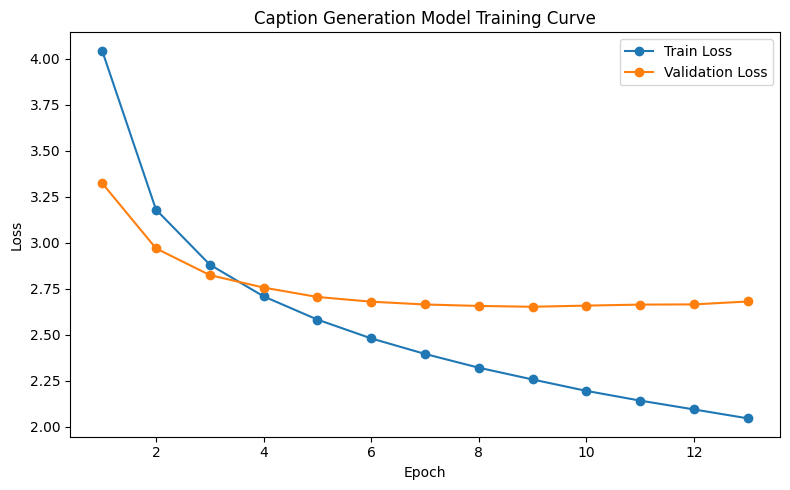

In [66]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Caption Generation Model Training Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "15_caption_gru_train_val_loss.png", dpi=300)
plt.show()

In [67]:
# Load best caption generation model

best_caption_model_path = CACHE_DIR / "best_caption_gru_model.pt"

caption_model.load_state_dict(torch.load(best_caption_model_path, map_location=device))
caption_model = caption_model.to(device)
caption_model.eval()

print("Best caption model loaded from:", best_caption_model_path)

Best caption model loaded from: F:\homeworks\data analysis\Flickr8k-Multimodal-NLP\cache\best_caption_gru_model.pt


In [68]:
# Greedy caption generation

def generate_caption_greedy(model, image_feature, word2idx, idx2word, max_len):
    model.eval()
    
    image_tensor = torch.tensor(image_feature, dtype=torch.float32).unsqueeze(0).to(device)
    
    generated_ids = []
    current_token = torch.tensor([[START_IDX]], dtype=torch.long).to(device)
    
    with torch.inference_mode():
        hidden = torch.tanh(model.image_to_hidden(image_tensor)).unsqueeze(0)
        
        for _ in range(max_len - 1):
            emb = model.embedding(current_token)
            output, hidden = model.gru(emb, hidden)
            logits = model.output_layer(output[:, -1, :])
            
            next_id = torch.argmax(logits, dim=-1).item()
            
            if next_id == END_IDX:
                break
            
            if next_id not in [PAD_IDX, START_IDX, END_IDX]:
                generated_ids.append(next_id)
            
            current_token = torch.tensor([[next_id]], dtype=torch.long).to(device)
    
    words = [idx2word[idx] for idx in generated_ids]
    caption = " ".join(words)
    
    return caption, words

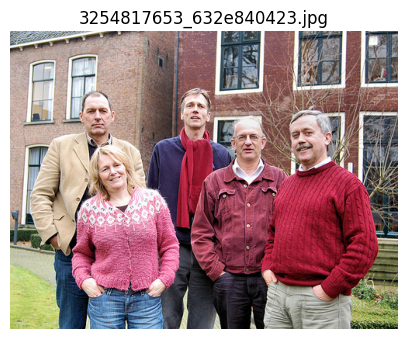

Image: 3254817653_632e840423.jpg
Generated: a group of people are standing in front of a brick building
References:
1. A family picture
2. A group of adults wear sweaters and have their hands in their pockets .
3. A group of five adults stand posing in front of buildings .
4. A group of people stand together and pose in front of a house .
5. A group shot of four guys and one girl in front of a brick building .


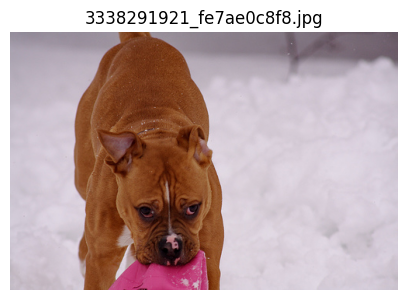

Image: 3338291921_fe7ae0c8f8.jpg
Generated: a brown and white dog is laying down in the snow
References:
1. A brown dog in the snow has something hot pink in its mouth .
2. A brown dog in the snow holding a pink hat .
3. A brown dog is holding a pink shirt in the snow .
4. A dog is carrying something pink in its mouth while walking through the snow .
5. A dog with something pink in its mouth is looking forward .


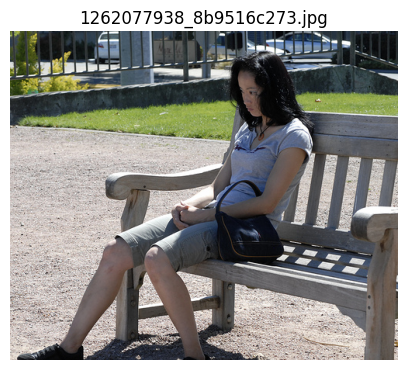

Image: 1262077938_8b9516c273.jpg
Generated: a woman in a blue shirt and jeans sits on a bench
References:
1. A girl with a black purse sitting on a wooden bench .
2. A woman sits alone on a park bench in the sun .
3. A woman with a handbag is sitting on a wooden bench .
4. A young asian woman wearing long shorts and a gray collared t-shirt is sitting on a wooden bench .
5. A young woman with a black purse sits on a wooden bench .


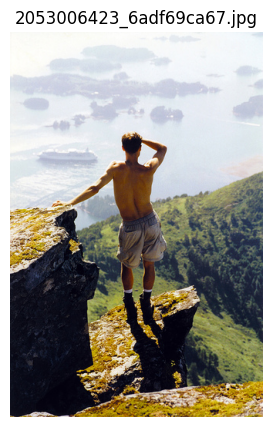

Image: 2053006423_6adf69ca67.jpg
Generated: a man in a blue shirt is standing on a rock in front of a large rock formation
References:
1. A man in shorts is standing on a rock looking out at the view from the hilltop .
2. a man looking at the view of a grassy mountain standing on a rock
3. A shirtless man standing on a rock overlooking a hillside .
4. Man with no shirt on wearing shorts and hiking boots standing with hand on his head looking out onto a mountain .
5. Shirtless man on high cliff with back to camera .


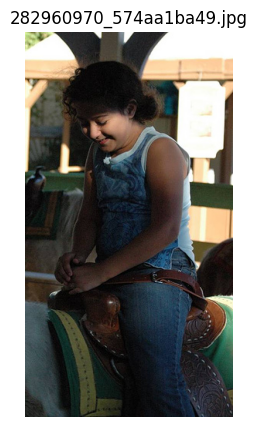

Image: 282960970_574aa1ba49.jpg
Generated: a man and a woman are sitting on a bench
References:
1. A person wearing jeans sits on top of a horse saddle .
2. A woman in jeans is sitting on the saddle of a horse .
3. The girl is sitting on top of a saddle .
4. The person is sitting on top of a horse .
5. This person is sitting in a saddle .


,image,generated_caption,reference_1,reference_2,reference_3,reference_4,reference_5
0,3254817653_632e840423.jpg,a group of people are standing in front of a b...,A family picture,A group of adults wear sweaters and have their...,A group of five adults stand posing in front o...,A group of people stand together and pose in f...,A group shot of four guys and one girl in fron...
1,3338291921_fe7ae0c8f8.jpg,a brown and white dog is laying down in the snow,A brown dog in the snow has something hot pink...,A brown dog in the snow holding a pink hat .,A brown dog is holding a pink shirt in the snow .,A dog is carrying something pink in its mouth ...,A dog with something pink in its mouth is look...
2,1262077938_8b9516c273.jpg,a woman in a blue shirt and jeans sits on a bench,A girl with a black purse sitting on a wooden ...,A woman sits alone on a park bench in the sun .,A woman with a handbag is sitting on a wooden ...,A young asian woman wearing long shorts and a ...,A young woman with a black purse sits on a woo...
3,2053006423_6adf69ca67.jpg,a man in a blue shirt is standing on a rock in...,A man in shorts is standing on a rock looking ...,a man looking at the view of a grassy mountain...,A shirtless man standing on a rock overlooking...,Man with no shirt on wearing shorts and hiking...,Shirtless man on high cliff with back to camera .
4,282960970_574aa1ba49.jpg,a man and a woman are sitting on a bench,A person wearing jeans sits on top of a horse ...,A woman in jeans is sitting on the saddle of a...,The girl is sitting on top of a saddle .,The person is sitting on top of a horse .,This person is sitting in a saddle .


In [69]:
# Generate captions for sample test images

np.random.seed(42)

sample_test_images = np.random.choice(
    sorted(test_df["image"].unique()),
    size=5,
    replace=False
)

sample_generation_rows = []

for img_name in sample_test_images:
    img_idx = image_to_idx[img_name]
    img_feature = X_caption_image_features[img_idx]
    
    generated_caption, generated_words = generate_caption_greedy(
        caption_model,
        img_feature,
        word2idx,
        idx2word,
        MAX_LEN
    )
    
    references = test_df[test_df["image"] == img_name]["caption"].tolist()
    
    sample_generation_rows.append({
        "image": img_name,
        "generated_caption": generated_caption,
        "reference_1": references[0],
        "reference_2": references[1],
        "reference_3": references[2],
        "reference_4": references[3],
        "reference_5": references[4]
    })
    
    img_path = IMAGES_DIR / img_name
    
    with Image.open(img_path) as img:
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(img_name)
        plt.show()
    
    print("=" * 100)
    print("Image:", img_name)
    print("Generated:", generated_caption)
    print("References:")
    for i, ref in enumerate(references, 1):
        print(f"{i}. {ref}")

sample_generation_df = pd.DataFrame(sample_generation_rows)

display(sample_generation_df)

sample_generation_df.to_csv(
    TABLES_DIR / "42_caption_generation_sample_outputs.csv",
    index=False
)

In [70]:
# Generate captions for all test images

test_unique_images = sorted(test_df["image"].unique())

generated_rows = []

for img_name in tqdm(test_unique_images, desc="Generating captions for test images"):
    img_idx = image_to_idx[img_name]
    img_feature = X_caption_image_features[img_idx]
    
    generated_caption, generated_words = generate_caption_greedy(
        caption_model,
        img_feature,
        word2idx,
        idx2word,
        MAX_LEN
    )
    
    refs = test_df[test_df["image"] == img_name]["clean_caption"].tolist()
    
    generated_rows.append({
        "image": img_name,
        "generated_caption": generated_caption,
        "generated_tokens": generated_words,
        "references": refs
    })

generated_test_df = pd.DataFrame(generated_rows)

display(generated_test_df.head())

generated_test_df.to_csv(
    TABLES_DIR / "43_caption_generation_test_predictions.csv",
    index=False
)

Generating captions for test images: 100%|██████████████████████████████████| 1214/1214 [00:04<00:00, 291.53it/s]


,image,generated_caption,generated_tokens,references
0,1000268201_693b08cb0e.jpg,a young boy stands in front of a large building,"[a, young, boy, stands, in, front, of, a, larg...",[a child in a pink dress is climbing up a set ...
1,1019604187_d087bf9a5f.jpg,a white dog is running through a grassy area,"[a, white, dog, is, running, through, a, grass...",[a dog prepares to catch a thrown object in a ...
2,1020651753_06077ec457.jpg,a white dog is running through a grassy field,"[a, white, dog, is, running, through, a, grass...",[a black and white dog jumping in the air to g...
3,1022454428_b6b660a67b.jpg,a man and a woman are sitting on a dock overlo...,"[a, man, and, a, woman, are, sitting, on, a, d...",[a couple and an infant being held by the male...
4,1028205764_7e8df9a2ea.jpg,a man in a blue kayak is paddling a kayak thro...,"[a, man, in, a, blue, kayak, is, paddling, a, ...",[a man and a baby are in a yellow kayak on wat...


In [71]:
# BLEU evaluation

from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

smooth = SmoothingFunction().method1

bleu_rows = []

for _, row in generated_test_df.iterrows():
    candidate = row["generated_caption"].split()
    references = [ref.split() for ref in row["references"]]
    
    if len(candidate) == 0:
        bleu1 = bleu2 = bleu3 = bleu4 = 0.0
    else:
        bleu1 = sentence_bleu(
            references, candidate,
            weights=(1.0, 0, 0, 0),
            smoothing_function=smooth
        )
        bleu2 = sentence_bleu(
            references, candidate,
            weights=(0.5, 0.5, 0, 0),
            smoothing_function=smooth
        )
        bleu3 = sentence_bleu(
            references, candidate,
            weights=(1/3, 1/3, 1/3, 0),
            smoothing_function=smooth
        )
        bleu4 = sentence_bleu(
            references, candidate,
            weights=(0.25, 0.25, 0.25, 0.25),
            smoothing_function=smooth
        )
    
    bleu_rows.append({
        "image": row["image"],
        "BLEU-1": bleu1,
        "BLEU-2": bleu2,
        "BLEU-3": bleu3,
        "BLEU-4": bleu4
    })

bleu_df = pd.DataFrame(bleu_rows)

bleu_summary_df = bleu_df[["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"]].mean().to_frame("mean_score")

display(bleu_summary_df)

bleu_df.to_csv(TABLES_DIR / "44_caption_generation_bleu_per_image.csv", index=False)
bleu_summary_df.to_csv(TABLES_DIR / "45_caption_generation_bleu_summary.csv")

,mean_score
BLEU-1,0.579399
BLEU-2,0.391918
BLEU-3,0.248007
BLEU-4,0.164560


In [72]:
# ROUGE-L evaluation

from rouge_score import rouge_scorer

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

rouge_rows = []

for _, row in generated_test_df.iterrows():
    candidate = row["generated_caption"]
    references = row["references"]
    
    if len(candidate.strip()) == 0:
        best_rouge_l = 0.0
    else:
        # چون هر تصویر 5 reference دارد، بهترین ROUGE-L بین referenceها را می‌گیریم
        scores = [
            rouge.score(ref, candidate)["rougeL"].fmeasure
            for ref in references
        ]
        best_rouge_l = max(scores)
    
    rouge_rows.append({
        "image": row["image"],
        "ROUGE-L": best_rouge_l
    })

rouge_df = pd.DataFrame(rouge_rows)

rouge_summary_df = rouge_df[["ROUGE-L"]].mean().to_frame("mean_score")

display(rouge_summary_df)

rouge_df.to_csv(TABLES_DIR / "46_caption_generation_rougeL_per_image.csv", index=False)
rouge_summary_df.to_csv(TABLES_DIR / "47_caption_generation_rougeL_summary.csv")

,mean_score
ROUGE-L,0.4519


In [73]:
# Final caption generation metrics summary

caption_metrics_summary_df = pd.DataFrame({
    "Metric": [
        "Best validation loss",
        "Best validation perplexity",
        "BLEU-1",
        "BLEU-2",
        "BLEU-3",
        "BLEU-4",
        "ROUGE-L"
    ],
    "Value": [
        best_val_loss,
        np.exp(best_val_loss),
        bleu_summary_df.loc["BLEU-1", "mean_score"],
        bleu_summary_df.loc["BLEU-2", "mean_score"],
        bleu_summary_df.loc["BLEU-3", "mean_score"],
        bleu_summary_df.loc["BLEU-4", "mean_score"],
        rouge_summary_df.loc["ROUGE-L", "mean_score"]
    ]
})

display(caption_metrics_summary_df)

caption_metrics_summary_df.to_csv(
    TABLES_DIR / "48_caption_generation_final_metrics_summary.csv",
    index=False
)

,Metric,Value
0,Best validation loss,2.651979
1,Best validation perplexity,14.182080
2,BLEU-1,0.579399
3,BLEU-2,0.391918
4,BLEU-3,0.248007
5,BLEU-4,0.164560
6,ROUGE-L,0.451900


In [74]:
# Combine caption generation metrics per image

caption_eval_df = generated_test_df.merge(bleu_df, on="image", how="left")
caption_eval_df = caption_eval_df.merge(rouge_df, on="image", how="left")

caption_eval_df["combined_score"] = (
    caption_eval_df["BLEU-1"] +
    caption_eval_df["BLEU-2"] +
    caption_eval_df["BLEU-3"] +
    caption_eval_df["BLEU-4"] +
    caption_eval_df["ROUGE-L"]
) / 5

display(caption_eval_df.head())

caption_eval_df.to_csv(
    TABLES_DIR / "49_caption_generation_full_evaluation_per_image.csv",
    index=False
)

,image,generated_caption,generated_tokens,references,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,combined_score
0,1000268201_693b08cb0e.jpg,a young boy stands in front of a large building,"[a, young, boy, stands, in, front, of, a, larg...",[a child in a pink dress is climbing up a set ...,0.500000,0.074536,0.041104,0.031560,0.352941,0.200028
1,1019604187_d087bf9a5f.jpg,a white dog is running through a grassy area,"[a, white, dog, is, running, through, a, grass...",[a dog prepares to catch a thrown object in a ...,0.777778,0.540062,0.436790,0.343295,0.588235,0.537232
2,1020651753_06077ec457.jpg,a white dog is running through a grassy field,"[a, white, dog, is, running, through, a, grass...",[a black and white dog jumping in the air to g...,0.695986,0.623897,0.530475,0.386275,0.583333,0.563993
3,1022454428_b6b660a67b.jpg,a man and a woman are sitting on a dock overlo...,"[a, man, and, a, woman, are, sitting, on, a, d...",[a couple and an infant being held by the male...,0.615385,0.320256,0.210475,0.098265,0.344828,0.317842
4,1028205764_7e8df9a2ea.jpg,a man in a blue kayak is paddling a kayak thro...,"[a, man, in, a, blue, kayak, is, paddling, a, ...",[a man and a baby are in a yellow kayak on wat...,0.615385,0.392232,0.111832,0.061154,0.434783,0.323077


In [75]:
# Best and worst caption generation examples

best_caption_examples_df = (
    caption_eval_df
    .sort_values("combined_score", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

worst_caption_examples_df = (
    caption_eval_df
    .sort_values("combined_score", ascending=True)
    .head(10)
    .reset_index(drop=True)
)

display(best_caption_examples_df[[
    "image", "generated_caption", "BLEU-1", "BLEU-4", "ROUGE-L", "combined_score"
]])

display(worst_caption_examples_df[[
    "image", "generated_caption", "BLEU-1", "BLEU-4", "ROUGE-L", "combined_score"
]])

best_caption_examples_df.to_csv(
    TABLES_DIR / "50_best_caption_generation_examples.csv",
    index=False
)

worst_caption_examples_df.to_csv(
    TABLES_DIR / "51_worst_caption_generation_examples.csv",
    index=False
)

,image,generated_caption,BLEU-1,BLEU-4,ROUGE-L,combined_score
0,3173461705_b5cdeef1eb.jpg,two dogs play in the snow,1.0,1.000000,1.000000,1.000000
1,3242919570_39a05aa2ee.jpg,a dog is running through the snow,1.0,1.000000,1.000000,1.000000
2,2282522980_45cfa8e0cf.jpg,two dogs play in the snow,1.0,1.000000,1.000000,1.000000
3,2114739371_83aa8bdb0e.jpg,a dog runs through the grass,1.0,1.000000,1.000000,1.000000
4,2867845624_22e4fe0a23.jpg,a black and white dog is running through the w...,1.0,0.962195,0.842105,0.960860
5,2552949275_b8cdc450cc.jpg,a dog is jumping into the water,1.0,0.880112,0.923077,0.946301
6,3203878596_cbb307ce3b.jpg,two brown dogs are playing in the snow,1.0,0.840896,0.933333,0.943053
7,895502702_5170ada2ee.jpg,a black and white dog is running through a gra...,1.0,0.914691,0.909091,0.940157
8,2629445284_83390e83af.jpg,a dog is jumping over a hurdle,1.0,0.930605,0.769231,0.939967
9,1348113612_5bfc5f429e.jpg,a dog jumps into a pool,1.0,1.000000,0.666667,0.933333


,image,generated_caption,BLEU-1,BLEU-4,ROUGE-L,combined_score
0,2288099178_41091aa00c.jpg,a boy wearing a red helmet is riding a skatebo...,0.000000,0.000000,0.100000,0.020000
1,2578161080_e007c9177a.jpg,a man and a woman walk down a paved road,0.100000,0.021105,0.125000,0.060695
2,1808504612_3508f3c9bb.jpg,a small child is jumping through a pile of leaves,0.100000,0.021105,0.125000,0.060695
3,1540631615_8b42c1b160.jpg,two young girls playing soccer,0.109762,0.029487,0.117647,0.065181
4,3549277110_24d4064ccd.jpg,a young boy wearing a red shirt is sitting on ...,0.076923,0.015537,0.190476,0.065250
5,835415474_7b7f2a9768.jpg,a young boy wearing a red shirt is wearing a r...,0.117647,0.013679,0.153846,0.065855
6,2255685792_f70474c6db.jpg,a man wearing a red jacket and a red hat is sk...,0.125000,0.014628,0.148148,0.066953
7,3638783842_af08dbb518.jpg,a woman in a white dress is holding a <unk> <unk>,0.090909,0.018850,0.222222,0.076750
8,581419370_30485f3580.jpg,a man is climbing a rock wall,0.142857,0.033032,0.142857,0.080757
9,1309330801_aeeb23f1ee.jpg,a man jumps over a small white and black and w...,0.153341,0.018636,0.190476,0.084206


Best Caption Generation Examples
----------------------------------------------------------------------------------------------------
Image: 3173461705_b5cdeef1eb.jpg
Generated: two dogs play in the snow
BLEU-1=1.000 | BLEU-4=1.000 | ROUGE-L=1.000
References:
  1. one dog is jumping up at another dog by a fence on a snowy day
  2. two blond dogs sniff one another
  3. two dogs in snow
  4. two dogs play in the snow
  5. two tan dogs play in the snow


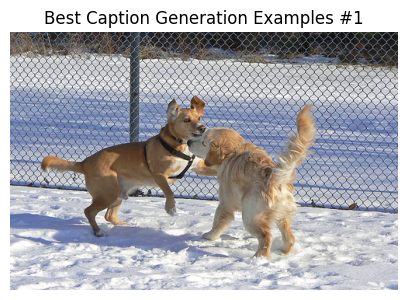

----------------------------------------------------------------------------------------------------
Image: 3242919570_39a05aa2ee.jpg
Generated: a dog is running through the snow
BLEU-1=1.000 | BLEU-4=1.000 | ROUGE-L=1.000
References:
  1. a dog is running through the snow
  2. a thin white dog is running through snow
  3. a white dog with black markings runs through the snow
  4. a white dog with red ears is running in the snow
  5. a white dog with tan ears is running through the snow


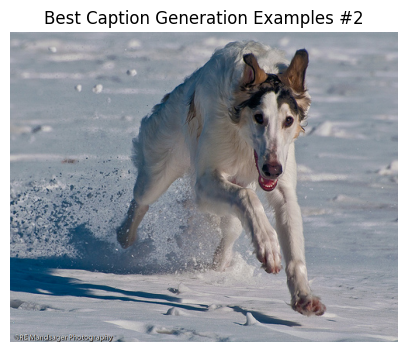

----------------------------------------------------------------------------------------------------
Image: 2282522980_45cfa8e0cf.jpg
Generated: two dogs play in the snow
BLEU-1=1.000 | BLEU-4=1.000 | ROUGE-L=1.000
References:
  1. the dog with the green collar and ball is running behind the dog with the red collar
  2. two dogs enjoy playing in the cold of the snow
  3. two dogs play in the snow
  4. two dogs play in the snow together
  5. two dogs run through the snow


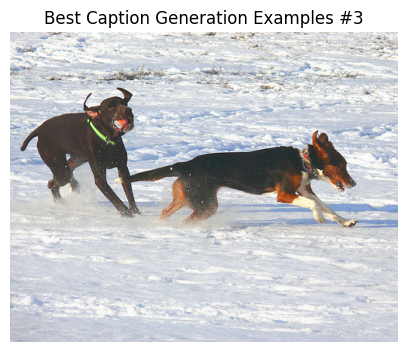

Worst Caption Generation Examples
----------------------------------------------------------------------------------------------------
Image: 2288099178_41091aa00c.jpg
Generated: a boy wearing a red helmet is riding a skateboard down a street
BLEU-1=0.000 | BLEU-4=0.000 | ROUGE-L=0.100
References:
  1. children skating while people watch on the side
  2. two boys ice skate with other people
  3. two boys on ice skates race on an outdoor ice rink
  4. two boys race on ice skates while others watch
  5. two children are skating quickly on ice


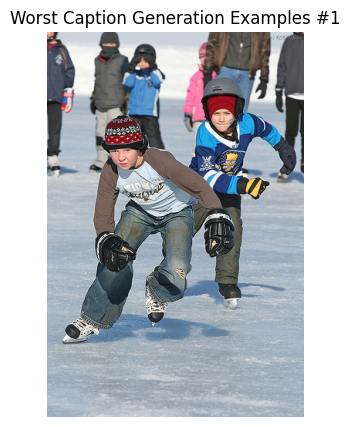

----------------------------------------------------------------------------------------------------
Image: 2578161080_e007c9177a.jpg
Generated: a man and a woman walk down a paved road
BLEU-1=0.100 | BLEU-4=0.021 | ROUGE-L=0.125
References:
  1. four men are standing outside in front of a fence
  2. four people are looking through a fence
  3. people are standing next to a chain link fence
  4. several men are watching something through a fence
  5. young men looking through a fence


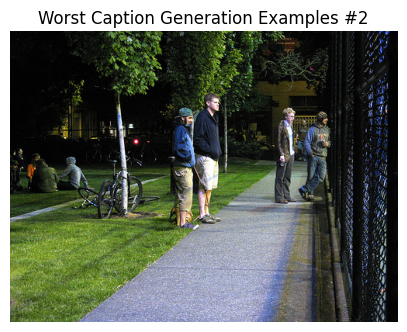

----------------------------------------------------------------------------------------------------
Image: 1808504612_3508f3c9bb.jpg
Generated: a small child is jumping through a pile of leaves
BLEU-1=0.100 | BLEU-4=0.021 | ROUGE-L=0.125
References:
  1. children climbing huge tree
  2. two children are sitting in some tree branches
  3. two children look down from a green tree they have climbed
  4. two kids in a green tree
  5. two people standing in tree on a sunny day


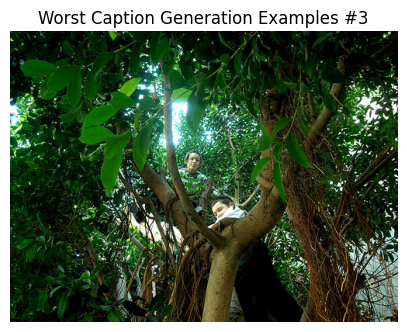

In [76]:
# Human-readable best/worst caption examples

def show_caption_generation_examples(examples_df, title, n=3, save_prefix=None):
    print("=" * 100)
    print(title)
    
    for i, row in examples_df.head(n).iterrows():
        img_name = row["image"]
        img_path = IMAGES_DIR / img_name
        
        print("-" * 100)
        print("Image:", img_name)
        print("Generated:", row["generated_caption"])
        print(f"BLEU-1={row['BLEU-1']:.3f} | BLEU-4={row['BLEU-4']:.3f} | ROUGE-L={row['ROUGE-L']:.3f}")
        print("References:")
        
        for j, ref in enumerate(row["references"], 1):
            print(f"  {j}. {ref}")
        
        with Image.open(img_path) as img:
            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.axis("off")
            plt.title(f"{title} #{i+1}")
            
            if save_prefix is not None:
                plt.savefig(
                    FIGURES_DIR / f"{save_prefix}_{i+1}.png",
                    dpi=300,
                    bbox_inches="tight"
                )
            
            plt.show()


show_caption_generation_examples(
    best_caption_examples_df,
    title="Best Caption Generation Examples",
    n=3,
    save_prefix="16_best_caption_example"
)

show_caption_generation_examples(
    worst_caption_examples_df,
    title="Worst Caption Generation Examples",
    n=3,
    save_prefix="17_worst_caption_example"
)

,generated_length,mean_reference_length
count,1214.000000,1214.000000
mean,10.509885,10.879736
std,3.006914,2.090823
min,4.000000,5.800000
25%,8.000000,9.400000
50%,10.000000,10.800000
75%,13.000000,12.000000
max,19.000000,19.800000


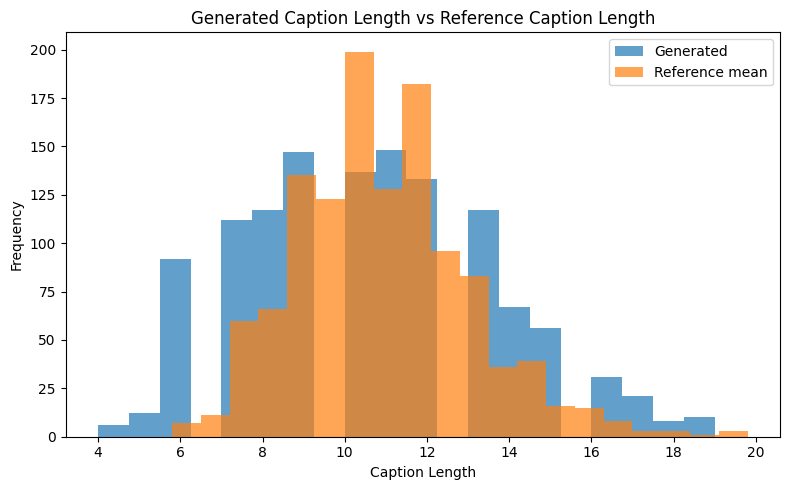

In [77]:
# Generated caption length analysis

caption_eval_df["generated_length"] = caption_eval_df["generated_caption"].apply(
    lambda x: len(str(x).split())
)

caption_eval_df["mean_reference_length"] = caption_eval_df["references"].apply(
    lambda refs: np.mean([len(ref.split()) for ref in refs])
)

length_summary_df = caption_eval_df[[
    "generated_length",
    "mean_reference_length"
]].describe()

display(length_summary_df)

length_summary_df.to_csv(
    TABLES_DIR / "52_generated_vs_reference_length_summary.csv"
)

plt.figure(figsize=(8, 5))
plt.hist(caption_eval_df["generated_length"], bins=20, alpha=0.7, label="Generated")
plt.hist(caption_eval_df["mean_reference_length"], bins=20, alpha=0.7, label="Reference mean")
plt.xlabel("Caption Length")
plt.ylabel("Frequency")
plt.title("Generated Caption Length vs Reference Caption Length")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "18_generated_vs_reference_caption_length.png", dpi=300)
plt.show()

In [78]:
# Final summary for Model 3

best_epoch = history_df.loc[history_df["val_loss"].idxmin(), "epoch"]

model3_summary_df = pd.DataFrame({
    "Item": [
        "Task",
        "Image representation",
        "Decoder",
        "Vocabulary size",
        "MIN_FREQ",
        "MAX_LEN",
        "Best epoch",
        "Best validation loss",
        "Best validation perplexity",
        "BLEU-1",
        "BLEU-2",
        "BLEU-3",
        "BLEU-4",
        "ROUGE-L",
        "Main strength",
        "Main limitation"
    ],
    "Value": [
        "Image caption generation",
        "Cached ResNet50 2048-dimensional features",
        "GRU decoder",
        len(word2idx),
        MIN_FREQ,
        MAX_LEN,
        int(best_epoch),
        best_val_loss,
        np.exp(best_val_loss),
        bleu_summary_df.loc["BLEU-1", "mean_score"],
        bleu_summary_df.loc["BLEU-2", "mean_score"],
        bleu_summary_df.loc["BLEU-3", "mean_score"],
        bleu_summary_df.loc["BLEU-4", "mean_score"],
        rouge_summary_df.loc["ROUGE-L", "mean_score"],
        "The model captures frequent objects, people, actions, and general scene structure.",
        "The model sometimes generates generic captions or hallucinates actions not present in the image."
    ]
})

display(model3_summary_df)

model3_summary_df.to_csv(
    TABLES_DIR / "53_model3_caption_generation_summary.csv",
    index=False
)

,Item,Value
0,Task,Image caption generation
1,Image representation,Cached ResNet50 2048-dimensional features
2,Decoder,GRU decoder
3,Vocabulary size,2482
4,MIN_FREQ,5
5,MAX_LEN,20
6,Best epoch,9
7,Best validation loss,2.651979
8,Best validation perplexity,14.18208
9,BLEU-1,0.579399


In [79]:
# Final comparison of the three modeling approaches

model_comparison_df = pd.DataFrame({
    "Model / Approach": [
        "Model 1: Multimodal Similarity Analysis",
        "Model 2: Image-Caption Matching",
        "Model 3: Image Caption Generation"
    ],
    "Main Task": [
        "Analyze image-image, caption-caption, and image-text semantic consistency",
        "Classify whether an image-caption pair is matched or mismatched",
        "Generate a natural-language caption for an input image"
    ],
    "Input": [
        "Image embeddings and text embeddings",
        "Image embedding + text embedding",
        "Image embedding"
    ],
    "Output": [
        "Nearest neighbors and visual-text overlap",
        "Matched / Mismatched probability",
        "Generated caption"
    ],
    "Main Method": [
        "ResNet50 + TF-IDF/SVD + cosine similarity",
        "ResNet50/PCA + TF-IDF/SVD + Logistic Regression",
        "ResNet50 features + GRU decoder"
    ],
    "Main Metrics": [
        "Top-5 visual-text neighbor overlap",
        "Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix",
        "Validation loss, Perplexity, BLEU, ROUGE-L"
    ],
    "Key Result": [
        "Mean top-5 visual-text overlap ratio = 0.062",
        "Test F1 = 0.753, ROC-AUC = 0.777 using threshold 0.31",
        "BLEU-1 = 0.576, BLEU-4 = 0.163, ROUGE-L = 0.451"
    ],
    "Strength": [
        "Shows that visual and textual spaces are related but not fully aligned",
        "Provides interpretable binary evaluation and confusion matrix",
        "Actually predicts the text space from the visual space"
    ],
    "Limitation": [
        "Does not predict or generate captions",
        "High false positives for semantically similar but incorrect captions",
        "Sometimes generates generic captions or hallucinates actions"
    ]
})

display(model_comparison_df)

model_comparison_df.to_csv(
    TABLES_DIR / "54_final_model_comparison.csv",
    index=False
)

,Model / Approach,Main Task,Input,Output,Main Method,Main Metrics,Key Result,Strength,Limitation
0,Model 1: Multimodal Similarity Analysis,"Analyze image-image, caption-caption, and imag...",Image embeddings and text embeddings,Nearest neighbors and visual-text overlap,ResNet50 + TF-IDF/SVD + cosine similarity,Top-5 visual-text neighbor overlap,Mean top-5 visual-text overlap ratio = 0.062,Shows that visual and textual spaces are relat...,Does not predict or generate captions
1,Model 2: Image-Caption Matching,Classify whether an image-caption pair is matc...,Image embedding + text embedding,Matched / Mismatched probability,ResNet50/PCA + TF-IDF/SVD + Logistic Regression,"Accuracy, Precision, Recall, F1, ROC-AUC, Conf...","Test F1 = 0.753, ROC-AUC = 0.777 using thresho...",Provides interpretable binary evaluation and c...,High false positives for semantically similar ...
2,Model 3: Image Caption Generation,Generate a natural-language caption for an inp...,Image embedding,Generated caption,ResNet50 features + GRU decoder,"Validation loss, Perplexity, BLEU, ROUGE-L","BLEU-1 = 0.576, BLEU-4 = 0.163, ROUGE-L = 0.451",Actually predicts the text space from the visu...,Sometimes generates generic captions or halluc...


In [80]:
# Bias-variance analysis for caption generation model

best_epoch_row = history_df.loc[history_df["val_loss"].idxmin()]

final_epoch_row = history_df.iloc[-1]

bias_variance_summary_df = pd.DataFrame({
    "Item": [
        "Best epoch",
        "Best train loss",
        "Best validation loss",
        "Final train loss",
        "Final validation loss",
        "Observation",
        "Interpretation"
    ],
    "Value": [
        int(best_epoch_row["epoch"]),
        best_epoch_row["train_loss"],
        best_epoch_row["val_loss"],
        final_epoch_row["train_loss"],
        final_epoch_row["val_loss"],
        "Training loss continued to decrease after the best validation epoch, while validation loss stopped improving.",
        "This indicates mild overfitting after epoch 9; early stopping prevented stronger overfitting."
    ]
})

display(bias_variance_summary_df)

bias_variance_summary_df.to_csv(
    TABLES_DIR / "55_bias_variance_caption_model_summary.csv",
    index=False
)

,Item,Value
0,Best epoch,9
1,Best train loss,2.256487
2,Best validation loss,2.651979
3,Final train loss,2.045075
4,Final validation loss,2.680695
5,Observation,Training loss continued to decrease after the ...
6,Interpretation,This indicates mild overfitting after epoch 9;...


In [81]:
# Limitations and future work

limitations_future_df = pd.DataFrame({
    "Limitation": [
        "Visual and textual embeddings were learned separately.",
        "TF-IDF cannot capture deep semantic meaning or paraphrases completely.",
        "The matching model used random negative samples.",
        "The caption generation model used a simple GRU decoder without attention.",
        "The caption generator sometimes produced generic captions.",
        "Automatic metrics such as BLEU and ROUGE do not fully capture semantic correctness."
    ],
    "Possible Improvement": [
        "Use jointly trained multimodal models such as CLIP-like contrastive learning.",
        "Use contextual sentence embeddings or transformer-based text encoders.",
        "Use hard negative mining to create more challenging mismatched pairs.",
        "Add attention mechanism or use a Transformer decoder.",
        "Use beam search, attention, or stronger visual features.",
        "Add qualitative human evaluation or semantic metrics."
    ]
})

display(limitations_future_df)

limitations_future_df.to_csv(
    TABLES_DIR / "56_limitations_and_future_work.csv",
    index=False
)

,Limitation,Possible Improvement
0,Visual and textual embeddings were learned sep...,Use jointly trained multimodal models such as ...
1,TF-IDF cannot capture deep semantic meaning or...,Use contextual sentence embeddings or transfor...
2,The matching model used random negative samples.,Use hard negative mining to create more challe...
3,The caption generation model used a simple GRU...,Add attention mechanism or use a Transformer d...
4,The caption generator sometimes produced gener...,"Use beam search, attention, or stronger visual..."
5,Automatic metrics such as BLEU and ROUGE do no...,Add qualitative human evaluation or semantic m...
